In [1]:
import pandas as pd

In [2]:
cams_metadata = pd.read_parquet("../dataset/CAMS AMCs NAVs 09052025/processed/product_metadata.parquet")
cams_navs = pd.read_parquet("../dataset/CAMS AMCs NAVs 09052025/processed/all_products.parquet")

kfintech_metadata = pd.read_parquet("../dataset/Kfintech AMCs NAVs 09052025/processed/fcode_desc_metadata.parquet")
kfintech_navs = pd.read_parquet("../dataset/Kfintech AMCs NAVs 09052025/processed/all_funds.parquet")


In [3]:
print("Dataset info:")

print("CAMS Metadata:")
display(cams_metadata.info())

print("CAMS NAVs:")
display(cams_navs.info())

print("Kfintech Metadata:")
display(kfintech_metadata.info())

print("Kfintech NAVs:")
display(kfintech_navs.info())

Dataset info:
CAMS Metadata:
<class 'pandas.DataFrame'>
RangeIndex: 26345 entries, 0 to 26344
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   PRODCODE    26345 non-null  str  
 1   NAME        26345 non-null  str  
 2   SCHEME_TYP  26345 non-null  str  
 3   ISIN_NO     26345 non-null  str  
dtypes: str(4)
memory usage: 3.0 MB


None

CAMS NAVs:
<class 'pandas.DataFrame'>
RangeIndex: 24421917 entries, 0 to 24421916
Data columns (total 6 columns):
 #   Column      Dtype  
---  ------      -----  
 0   PRODCODE    str    
 1   NAV_DATE    object 
 2   NAV_VALUE   float64
 3   DIV_PERUNI  float64
 4   CORPDIVRAT  float64
 5   SWING_NAV   float64
dtypes: float64(4), object(1), str(1)
memory usage: 1.2+ GB


None

Kfintech Metadata:
<class 'pandas.DataFrame'>
RangeIndex: 15594 entries, 0 to 15593
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   FCODE_DESC_ID  15594 non-null  int64         
 1   FCODE          15594 non-null  str           
 2   FUND           15594 non-null  str           
 3   SCHEME         15594 non-null  str           
 4   SCHEMEISIN     13127 non-null  str           
 5   CRDATE         15594 non-null  datetime64[us]
 6   CRTIME         15594 non-null  int64         
 7   FUNDDESC       15594 non-null  str           
dtypes: datetime64[us](1), int64(2), str(5)
memory usage: 2.2 MB


None

Kfintech NAVs:
<class 'pandas.DataFrame'>
RangeIndex: 16093603 entries, 0 to 16093602
Data columns (total 5 columns):
 #   Column         Dtype         
---  ------         -----         
 0   NAVDATE        datetime64[us]
 1   NAV            float64       
 2   RPOP           float64       
 3   PPOP           float64       
 4   FCODE_DESC_ID  int64         
dtypes: datetime64[us](1), float64(3), int64(1)
memory usage: 613.9 MB


None

In [4]:
print("CAMS unique PRODCODE:",
      cams_metadata["PRODCODE"].nunique())

print("CAMS unique ISIN:",
      cams_metadata["ISIN_NO"].nunique())

print("Kfintech unique FCODE:",
      kfintech_metadata["FCODE"].nunique())

print("Kfintech unique FCODE_DESC_ID:",
      kfintech_metadata["FCODE_DESC_ID"].nunique())

print("Kfintech unique SCHEMEISIN:",
      kfintech_metadata["SCHEMEISIN"].nunique())

CAMS unique PRODCODE: 26345
CAMS unique ISIN: 21248
Kfintech unique FCODE: 15387
Kfintech unique FCODE_DESC_ID: 15594
Kfintech unique SCHEMEISIN: 12809


In [5]:
print("CAMS")
print("ISINs occurring more than once:",
      (cams_metadata["ISIN_NO"].value_counts() > 1).sum())

print("Maximum records for one ISIN:",
      cams_metadata["ISIN_NO"].value_counts().max())


print("\nKfintech")
print("SCHEMEISINs occurring more than once:",
      (kfintech_metadata["SCHEMEISIN"].value_counts() > 1).sum())

print("Maximum records for one SCHEMEISIN:",
      kfintech_metadata["SCHEMEISIN"].value_counts().max())

CAMS
ISINs occurring more than once: 3
Maximum records for one ISIN: 5001

Kfintech
SCHEMEISINs occurring more than once: 211
Maximum records for one SCHEMEISIN: 55


In [6]:
invalid_isins = {"UNCLAIMDISIN", "ACTVNOINFLOW"}

cams_valid = cams_metadata[
    ~cams_metadata["ISIN_NO"].isin(invalid_isins)
]

kfin_valid = kfintech_metadata[
    ~kfintech_metadata["SCHEMEISIN"].isin(invalid_isins)
]

print("CAMS valid ISIN duplicates:",
      cams_valid["ISIN_NO"].duplicated().sum())

print("Kfintech valid SCHEMEISIN duplicates:",
      kfin_valid["SCHEMEISIN"].duplicated().sum())

print("CAMS valid unique ISINs:",
      cams_valid["ISIN_NO"].nunique())

print("Kfintech valid unique SCHEMEISINs:",
      kfin_valid["SCHEMEISIN"].nunique())

CAMS valid ISIN duplicates: 5000
Kfintech valid SCHEMEISIN duplicates: 2727
CAMS valid unique ISINs: 21246
Kfintech valid unique SCHEMEISINs: 12807


In [7]:
cams_valid = cams_metadata[
    ~cams_metadata["ISIN_NO"].isin(["UNCLAIMDISIN", "ACTVNOINFLOW"])
]

cams_isin_counts = (
    cams_valid
    .groupby("ISIN_NO")
    .size()
    .sort_values(ascending=False)
)

cams_isin_counts.head(20)

ISIN_NO
                5001
INF03VN01019       1
INF03VN01027       1
INF03VN01035       1
INF03VN01043       1
INF03VN01050       1
INF03VN01068       1
INF03VN01076       1
INF03VN01084       1
INF03VN01092       1
INF03VN01100       1
INF03VN01118       1
INF03VN01126       1
INF03VN01134       1
INF03VN01142       1
INF03VN01159       1
INF03VN01167       1
INF03VN01175       1
INF03VN01183       1
INF03VN01191       1
dtype: int64

In [8]:
top_cams_isins = cams_isin_counts.head(10).index


cams_valid[
    cams_valid["ISIN_NO"].isin(top_cams_isins)
].sort_values("ISIN_NO").groupby("ISIN_NO").head()

,PRODCODE,NAME,SCHEME_TYP,ISIN_NO
25,B1005,Aditya Birla Sun Life Asset Allocator FoF - IDCW,FOF,
26,B1005A,Aditya Birla Sun Life Asset Allocator FOF Dire...,FOF,
29,B1005P,Aditya Birla Sun Life Asset Allocator FoF - ID...,FOF,
30,B1006,Aditya Birla Sun Life Asset Allocator FoF - Gr...,FOF,
32,B1007,Aditya Birla Sun Life Erstwhile ING OptiMix Dy...,FOF,
26320,YLDDD,WhiteOak Capital - Liquid Fund - Direct Daily ...,Cash,INF03VN01019
26323,YLFDDP,WhiteOak Capital - Liquid Fund - Direct Fortni...,Cash,INF03VN01027
26322,YLFDD,WhiteOak Capital - Liquid Fund - Direct Fortni...,Cash,INF03VN01035
26326,YLGD,WhiteOak Capital - Liquid Fund - Direct Growth,Cash,INF03VN01043
26329,YLMDDP,WhiteOak Capital - Liquid Fund - Direct Monthl...,Cash,INF03VN01050


In [9]:
kfin_valid = kfintech_metadata[
    ~kfintech_metadata["SCHEMEISIN"].isin(["UNCLAIMDISIN", "ACTVNOINFLOW"])
]

kfin_isin_counts = (
    kfin_valid
    .groupby("SCHEMEISIN")
    .size()
    .sort_values(ascending=False)
)

kfin_isin_counts.head(20)

SCHEMEISIN
INF457M01133    19
INF173K01HC6     4
INF173K01CI4     3
INF754K01UQ6     3
INF173K01HJ1     3
INF173K01EL4     3
INF173K01ES9     3
INF173K01CV7     3
INF173K01FT4     3
INF173K01CW5     3
INF173K01197     3
INF173K01CX3     3
INF173K01EW1     3
INF754K01UU8     3
INF173K01247     3
INF173K01262     3
INF173K01DB7     3
INF173K01DC5     3
INF173K01FB2     3
INF173K01551     3
dtype: int64

In [10]:
top_kfin_isins = kfin_isin_counts.head(10).index


kfin_valid[
    kfin_valid["SCHEMEISIN"].isin(top_kfin_isins)
].sort_values("SCHEMEISIN").groupby("SCHEMEISIN").head()


,FCODE_DESC_ID,FCODE,FUND,SCHEME,SCHEMEISIN,CRDATE,CRTIME,FUNDDESC
11299,11300,176SBDP,176,SBDP,INF173K01CI4,2025-05-11,164331,SUNDARAM AGGRESSIVE HYBRID FUND - REGULAR PLAN...
11300,11301,176SBDP,176,SBDP,INF173K01CI4,2025-05-11,164331,SUNDARAM AGGRESSIVE HYBRID FUND - REGULAR PLAN...
11301,11302,176SBDP,176,SBDP,INF173K01CI4,2025-05-11,164331,SUNDARAM AGGRESSIVE HYBRID FUND - REGULAR PLAN...
11418,11419,176UTID,176,UTID,INF173K01CV7,2025-05-11,164331,SUNDARAM ULTRA SHORT DURATION FUND - IDCW PLAN...
11419,11420,176UTID,176,UTID,INF173K01CV7,2025-05-11,164331,SUNDARAM ULTRA SHORT DURATION FUND - IDCW PLAN...
11420,11421,176UTID,176,UTID,INF173K01CV7,2025-05-11,164331,SUNDARAM ULTRA SHORT DURATION FUND - REGULAR P...
11425,11426,176UTIW,176,UTIW,INF173K01CW5,2025-05-11,164331,SUNDARAM ULTRA SHORT DURATION FUND - IDCW PLAN...
11426,11427,176UTIW,176,UTIW,INF173K01CW5,2025-05-11,164331,SUNDARAM ULTRA SHORT DURATION FUND - IDCW PLAN...
11427,11428,176UTIW,176,UTIW,INF173K01CW5,2025-05-11,164331,SUNDARAM ULTRA SHORT DURATION FUND - REGULAR P...
10968,10969,176LCZD,176,LCZD,INF173K01EL4,2025-05-11,164331,SUNDARAM FOCUSED FUND - DIRECT PLAN HALF YEARL...


In [11]:
print("CAMS unique products:",
      cams_navs["PRODCODE"].nunique())

print("CAMS unique dates:",
      cams_navs["NAV_DATE"].nunique())

print("\nKfintech unique products:",
      kfintech_navs["FCODE_DESC_ID"].nunique())

print("Kfintech unique dates:",
      kfintech_navs["NAVDATE"].nunique())

CAMS unique products: 26345
CAMS unique dates: 11036

Kfintech unique products: 15594
Kfintech unique dates: 12563


In [12]:
cams_obs_per_product = (
    cams_navs.groupby("PRODCODE")
    .size()
)

cams_obs_per_product.describe()

count    26345.000000
mean       927.003872
std       1173.095105
min          1.000000
25%        136.000000
50%        694.000000
75%       1094.000000
max       8453.000000
dtype: float64

In [13]:
kfin_obs_per_product = (
    kfintech_navs.groupby("FCODE_DESC_ID")
    .size()
)

kfin_obs_per_product.describe()

count    15594.000000
mean      1032.038156
std       1231.380184
min          1.000000
25%        242.000000
50%        726.000000
75%       1199.000000
max       9611.000000
dtype: float64

In [14]:
print("CAMS products with only 1 observation:",
      (cams_obs_per_product == 1).sum())

print("Kfintech products with only 1 observation:",
      (kfin_obs_per_product == 1).sum())

CAMS products with only 1 observation: 2498
Kfintech products with only 1 observation: 325


In [15]:
cams_navs["NAV_DATE"] = pd.to_datetime(cams_navs["NAV_DATE"])
cams_navs["YEAR"] = cams_navs["NAV_DATE"].dt.year

cams_yearly = (
    cams_navs.groupby("YEAR")
    .size()
)

cams_yearly

YEAR
1990          1
1993         12
1994        561
1995       1625
1996       3232
1997      11861
1998      21595
1999      39428
2000      69904
2001     103867
2002     139843
2003     183413
2004     253825
2005     273669
2006     342239
2007     457028
2008     597452
2009     545936
2010     543586
2011     689082
2012     838881
2013    1343235
2014    1756866
2015    1802308
2016    1844892
2017    1630279
2018    1541137
2019    1689467
2020    1674778
2021    1505465
2022    1336610
2023    1295367
2024    1372652
2025     511821
dtype: int64

In [16]:
kfintech_navs["YEAR"] = kfintech_navs["NAVDATE"].dt.year

kfin_yearly = (
    kfintech_navs.groupby("YEAR")
    .size()
)

kfin_yearly

YEAR
1990        706
1991        772
1992       1080
1993       2017
1994       2706
1995       3239
1996       5252
1997       6828
1998      12441
1999      16364
2000      27395
2001      34258
2002      48817
2003      78233
2004     121685
2005     145961
2006     174057
2007     259015
2008     390153
2009     383674
2010     366425
2011     434044
2012     478183
2013     800027
2014    1033493
2015    1168943
2016    1236475
2017    1230213
2018    1166772
2019    1176481
2020    1156240
2021    1020193
2022     891221
2023     904529
2024     958761
2025     356950
dtype: int64

In [17]:
cams_products_yearly = (
    cams_navs.groupby(cams_navs["NAV_DATE"].dt.year)["PRODCODE"]
    .nunique()
)

print("CAMS active products by year:")
cams_products_yearly

CAMS active products by year:


NAV_DATE
1990       1
1993       6
1994       8
1995      17
1996      24
1997      76
1998     127
1999     237
2000     379
2001     531
2002     686
2003     951
2004    1217
2005    1295
2006    1813
2007    2994
2008    3951
2009    3159
2010    2749
2011    3939
2012    4579
2013    8046
2014    9463
2015    8479
2016    8131
2017    7755
2018    8195
2019    7611
2020    7074
2021    6924
2022    6318
2023    5547
2024    5803
2025    5833
Name: PRODCODE, dtype: int64

In [18]:
kfin_products_yearly = (
    kfintech_navs.groupby(kfintech_navs["NAVDATE"].dt.year)["FCODE_DESC_ID"]
    .nunique()
)

print("\nKfintech active products by year:")
kfin_products_yearly


Kfintech active products by year:


NAVDATE
1990       5
1991       5
1992       8
1993      19
1994      21
1995      31
1996      38
1997      51
1998      71
1999     108
2000     158
2001     170
2002     253
2003     418
2004     613
2005     722
2006     958
2007    1725
2008    2683
2009    2235
2010    1930
2011    2331
2012    2582
2013    4386
2014    5597
2015    5673
2016    5724
2017    5784
2018    5859
2019    5417
2020    5095
2021    4839
2022    4327
2023    4018
2024    4227
2025    4269
Name: FCODE_DESC_ID, dtype: int64

In [19]:
cams_avg_obs = cams_yearly / cams_products_yearly

print("CAMS average observations per active product:")
cams_avg_obs


CAMS average observations per active product:


YEAR
1990      1.000000
1993      2.000000
1994     70.125000
1995     95.588235
1996    134.666667
1997    156.065789
1998    170.039370
1999    166.362869
2000    184.443272
2001    195.606403
2002    203.852770
2003    192.863302
2004    208.566146
2005    211.327413
2006    188.769443
2007    152.647963
2008    151.215389
2009    172.819247
2010    197.739542
2011    174.938309
2012    183.201791
2013    166.944444
2014    185.656346
2015    212.561387
2016    226.896077
2017    210.222953
2018    188.058206
2019    221.977007
2020    236.751202
2021    217.427065
2022    211.555872
2023    233.525690
2024    236.541789
2025     87.745757
dtype: float64

In [20]:
kfin_avg_obs = kfin_yearly / kfin_products_yearly
print("\nKfintech average observations per active product:")
kfin_avg_obs


Kfintech average observations per active product:


YEAR
1990    141.200000
1991    154.400000
1992    135.000000
1993    106.157895
1994    128.857143
1995    104.483871
1996    138.210526
1997    133.882353
1998    175.225352
1999    151.518519
2000    173.386076
2001    201.517647
2002    192.952569
2003    187.160287
2004    198.507341
2005    202.162050
2006    181.687891
2007    150.153623
2008    145.416698
2009    171.666219
2010    189.857513
2011    186.205062
2012    185.198683
2013    182.404697
2014    184.651242
2015    206.053763
2016    216.015898
2017    212.692427
2018    199.141833
2019    217.183127
2020    226.936212
2021    210.827237
2022    205.967414
2023    225.119214
2024    226.818311
2025     83.614430
dtype: float64

In [21]:
print("CAMS missing values:")
print(cams_navs.isna().sum())

print("\nKfintech missing values:")
print(kfintech_navs.isna().sum())

CAMS missing values:
PRODCODE             0
NAV_DATE             0
NAV_VALUE            0
DIV_PERUNI           0
CORPDIVRAT     2790906
SWING_NAV     21919511
YEAR                 0
dtype: int64

Kfintech missing values:
NAVDATE                0
NAV                    0
RPOP             1888785
PPOP             1888785
FCODE_DESC_ID          0
YEAR                   0
dtype: int64


In [22]:
cams_zero_nav = (cams_navs["NAV_VALUE"] == 0).sum()
kfin_zero_nav = (kfintech_navs["NAV"] == 0).sum()

print("CAMS zero NAVs:", cams_zero_nav)
print("Kfintech zero NAVs:", kfin_zero_nav)

CAMS zero NAVs: 40221
Kfintech zero NAVs: 78930


In [23]:
print("CAMS duplicate rows:",
      cams_navs.duplicated().sum())

print("Kfintech duplicate rows:",
      kfintech_navs.duplicated().sum())

CAMS duplicate rows: 3081
Kfintech duplicate rows: 53


In [24]:
cams_duplicates = cams_navs[cams_navs.duplicated(keep=False)]

print("CAMS duplicate rows:", len(cams_duplicates))
cams_duplicates.sort_values(
    ["PRODCODE", "NAV_DATE"]
).head(20)

CAMS duplicate rows: 6156


,PRODCODE,NAV_DATE,NAV_VALUE,DIV_PERUNI,CORPDIVRAT,SWING_NAV,YEAR
1780358,B281,2006-10-05,10.0000,0.0,0.0,NaN,2006
1780359,B281,2006-10-05,10.0000,0.0,0.0,NaN,2006
1791659,B290,2007-02-19,10.0000,0.0,NaN,NaN,2007
1791660,B290,2007-02-19,10.0000,0.0,NaN,NaN,2007
1873440,B295DR,2012-03-07,11.3145,0.0,0.0,NaN,2012
1873441,B295DR,2012-03-07,11.3145,0.0,0.0,NaN,2012
1969824,B301DZ,2013-09-17,12.2213,0.0,0.0,NaN,2013
1969825,B301DZ,2013-09-17,12.2213,0.0,0.0,NaN,2013
1990805,B301QD,2013-09-17,12.0925,0.0,0.0,NaN,2013
1990806,B301QD,2013-09-17,12.0925,0.0,0.0,NaN,2013


In [25]:
kfin_duplicates = kfintech_navs[kfintech_navs.duplicated(keep=False)]

print("Kfintech duplicate rows:", len(kfin_duplicates))
kfin_duplicates.sort_values(
    ["FCODE_DESC_ID", "NAVDATE"]
).head(20)

Kfintech duplicate rows: 62


,NAVDATE,NAV,RPOP,PPOP,FCODE_DESC_ID,YEAR
2352900,2006-09-14,10.0000,10.0000,10.0000,1716,2006
2352901,2006-09-14,10.0000,10.0000,10.0000,1716,2006
2352923,2006-09-14,10.0000,10.0000,10.0000,1717,2006
2352924,2006-09-14,10.0000,10.0000,10.0000,1717,2006
9494669,2014-01-25,100.5392,100.5392,100.5392,8823,2014
9494670,2014-01-25,100.5392,100.5392,100.5392,8823,2014
12772184,2011-04-14,1006.0600,1006.0600,1006.0600,12248,2011
12772185,2011-04-14,1006.0600,1006.0600,1006.0600,12248,2011
12772186,2011-04-14,1006.0600,1006.0600,1006.0600,12248,2011
12772187,2011-04-14,1006.0600,1006.0600,1006.0600,12248,2011


In [26]:
print("CAMS duplicate group sizes:")
display(
    cams_duplicates
    .groupby(["PRODCODE", "NAV_DATE"])
    .size()
    .value_counts()
    .sort_index()
)


print("\nKfintech duplicate group sizes:")
display(
    kfin_duplicates
    .groupby(["FCODE_DESC_ID", "NAVDATE"])
    .size()
    .value_counts()
    .sort_index()
)

CAMS duplicate group sizes:


2    3066
3       5
4       1
5       1
Name: count, dtype: int64


Kfintech duplicate group sizes:


2     3
9     5
11    1
Name: count, dtype: int64

In [27]:
cams_navs[
    (cams_navs["PRODCODE"] == "B02") &
    (cams_navs["NAV_DATE"].isin(pd.to_datetime([
        "2006-04-27",
        "2006-12-08",
        "2007-01-19"
    ])))
].sort_values("NAV_DATE")

,PRODCODE,NAV_DATE,NAV_VALUE,DIV_PERUNI,CORPDIVRAT,SWING_NAV,YEAR
2450,B02,2006-04-27,224.51,0.0,0.0,NaN,2006
2451,B02,2006-04-27,174.51,0.0,NaN,NaN,2006
2607,B02,2006-12-08,168.94,0.0,0.0,NaN,2006
2608,B02,2006-12-08,193.94,0.0,0.0,NaN,2006
2636,B02,2007-01-19,176.54,0.0,0.0,NaN,2007
2637,B02,2007-01-19,150.54,0.0,0.0,NaN,2007


In [28]:
print(cams_metadata[
    cams_metadata["PRODCODE"] == "B02"
].to_string(index=False))

PRODCODE                                                                                    NAME SCHEME_TYP      ISIN_NO
     B02 Aditya Birla Sun Life ELSS Tax Saver Fund- (ELSS U/S 80C of IT ACT) - IDCW-Regular Plan       ELSS INF209K01090


In [29]:
cams_nav_ranges = (
    cams_navs
    .groupby(["PRODCODE", "NAV_DATE"])["NAV_VALUE"]
    .agg(["min", "max", "nunique"])
)

cams_nav_ranges["difference"] = (
    cams_nav_ranges["max"] - cams_nav_ranges["min"]
)

cams_nav_ranges[
    cams_nav_ranges["nunique"] > 1
].sort_values("difference", ascending=False).head(10)

,,min,max,nunique,difference
PRODCODE,NAV_DATE,,,,
L347IG,2009-10-06,10.1076,1010.8735,4,1000.7659
L347RG,2009-10-06,10.1037,1010.3731,2,1000.2694
L347ID,2009-10-06,10.0056,1000.6703,4,990.6647
L347RD,2009-10-06,10.0062,1000.6163,3,990.6101
L347RW,2009-10-06,10.0062,1000.6162,2,990.6100
K45,2017-07-10,241.6094,984.3067,4,742.6973
OLCDG,2014-03-18,1037.8730,1729.7884,2,691.9154
OLCG,2014-03-18,1036.4327,1727.3877,2,690.9550
K120,2017-01-11,189.6135,847.6996,3,658.0861


In [30]:
cams_metadata[
    cams_metadata["PRODCODE"].isin([
        "L347IG",
        "L347RG",
        "L347ID",
        "L347RD",
        "L347RW"
    ])
]

,PRODCODE,NAME,SCHEME_TYP,ISIN_NO
16126,L347ID,SBI Liquid Fund - Institutional Plan - Daily IDCW,Cash,
16127,L347IG,SBI Liquid Fund - Institutional Plan - Growth ...,Cash,
16129,L347RD,SBI Liquid Fund - Regular Plan - Daily IDCW,Cash,
16130,L347RG,SBI Liquid Fund - Regular Plan - Growth Option,Cash,
16131,L347RW,SBI Liquid Fund - Regular Plan - Weekly IDCW,Cash,


In [31]:
l347ig = cams_navs[
    cams_navs["PRODCODE"] == "L347IG"
].sort_values("NAV_DATE")


l347ig[
    (l347ig["NAV_DATE"] >= pd.Timestamp("2009-09-25")) &
    (l347ig["NAV_DATE"] <= pd.Timestamp("2009-10-20"))
]

,PRODCODE,NAV_DATE,NAV_VALUE,DIV_PERUNI,CORPDIVRAT,SWING_NAV,YEAR
13851037,L347IG,2009-09-25,10.0955,0.0,NaN,NaN,2009
13851038,L347IG,2009-09-28,10.0992,0.0,NaN,NaN,2009
13851039,L347IG,2009-09-29,10.1004,0.0,NaN,NaN,2009
13851040,L347IG,2009-09-30,10.1017,0.0,NaN,NaN,2009
13851041,L347IG,2009-10-01,10.1029,0.0,NaN,NaN,2009
13851042,L347IG,2009-10-04,10.1064,0.0,NaN,NaN,2009
13851043,L347IG,2009-10-05,10.1076,0.0,NaN,NaN,2009
13851044,L347IG,2009-10-06,1010.8735,0.0,NaN,NaN,2009
13851045,L347IG,2009-10-06,10.1087,0.0,NaN,NaN,2009
13851046,L347IG,2009-10-06,10.1076,0.0,NaN,NaN,2009


In [32]:
cams_navs = (
    cams_navs
    .drop_duplicates(
        subset=["PRODCODE", "NAV_DATE"],
        keep="last"
    )
    .reset_index(drop=True)
)

In [33]:
kfintech_navs = (
    kfintech_navs
    .drop_duplicates(
        subset=["FCODE_DESC_ID", "NAVDATE"],
        keep="last"
    )
    .reset_index(drop=True)
)

In [34]:
print("CAMS:", len(cams_navs))
print("Kfintech:", len(kfintech_navs))

print(
    "CAMS remaining conflicts:",
    cams_navs.duplicated(["PRODCODE", "NAV_DATE"]).sum()
)

print(
    "Kfintech remaining conflicts:",
    kfintech_navs.duplicated(["FCODE_DESC_ID", "NAVDATE"]).sum()
)

CAMS: 24270323
Kfintech: 16091745
CAMS remaining conflicts: 0
Kfintech remaining conflicts: 0


In [35]:
import numpy as np

In [36]:
cams_navs = cams_navs.sort_values(["PRODCODE", "NAV_DATE"])

prev_nav = cams_navs.groupby("PRODCODE")["NAV_VALUE"].shift()

cams_navs["RETURN"] = (
    cams_navs["NAV_VALUE"].div(prev_nav).sub(1)
)

cams_navs.loc[prev_nav == 0, "RETURN"] = np.nan

In [37]:
kfintech_navs = kfintech_navs.sort_values(["FCODE_DESC_ID", "NAVDATE"])

prev_nav = kfintech_navs.groupby("FCODE_DESC_ID")["NAV"].shift()

kfintech_navs["RETURN"] = (
    kfintech_navs["NAV"].div(prev_nav).sub(1)
)

kfintech_navs.loc[prev_nav == 0, "RETURN"] = np.nan

In [38]:
cams_return_stats = (
    cams_navs
    .groupby("PRODCODE")["RETURN"]
    .agg(
        observations="count",
        mean_return="mean",
        median_return="median",
        volatility="std",
        min_return="min",
        max_return="max"
    )
)

print("CAMS")
cams_return_stats.describe()

CAMS


,observations,mean_return,median_return,volatility,min_return,max_return
count,26345.000000,23826.000000,23826.000000,23505.000000,23826.000000,23826.000000
mean,918.724578,0.000466,0.000403,0.014967,-0.048564,0.343899
std,1163.137815,0.035874,0.032584,0.231102,0.090229,6.114894
min,0.000000,-1.000000,-1.000000,0.000000,-1.000000,-1.000000
25%,130.000000,0.000019,0.000217,0.000528,-0.068718,0.002246
50%,677.000000,0.000257,0.000256,0.002146,-0.018254,0.004755
75%,1093.000000,0.000364,0.000314,0.005816,-0.002938,0.022663
max,8452.000000,4.500000,4.500000,19.531859,0.002270,443.245614


In [39]:
kfintech_return_stats = (
    kfintech_navs
    .groupby("FCODE_DESC_ID")["RETURN"]
    .agg(
        observations="count",
        mean_return="mean",
        median_return="median",
        volatility="std",
        min_return="min",
        max_return="max"
    )
)

print("Kfintech")
kfintech_return_stats.describe()

Kfintech


,observations,mean_return,median_return,volatility,min_return,max_return
count,15594.000000,15177.000000,15177.000000,15113.000000,15177.000000,15177.000000
mean,1025.875593,0.016305,0.014260,0.057809,-0.050768,2.485945
std,1232.808004,1.210758,1.206326,0.774918,1.211320,42.482526
min,0.000000,-1.000000,-1.000000,0.000000,-1.000000,-1.000000
25%,241.000000,0.000019,0.000224,0.000717,-0.086216,0.002557
50%,725.000000,0.000272,0.000262,0.002946,-0.027273,0.005690
75%,1162.000000,0.000384,0.000312,0.007890,-0.004314,0.033841
max,9610.000000,110.735710,110.735710,77.430336,110.735710,4917.892857


In [40]:
cams_navs[cams_navs["PRODCODE"] == "B02"].head(10)

,PRODCODE,NAV_DATE,NAV_VALUE,DIV_PERUNI,CORPDIVRAT,SWING_NAV,YEAR,RETURN
0,B02,1996-03-31,10.00,0.0,NaN,NaN,1996,NaN
1,B02,1996-05-27,9.78,0.0,NaN,NaN,1996,-0.022000
2,B02,1996-05-28,9.76,0.0,NaN,NaN,1996,-0.002045
3,B02,1996-05-29,10.01,0.0,NaN,NaN,1996,0.025615
4,B02,1996-05-30,10.02,0.0,NaN,NaN,1996,0.000999
5,B02,1996-05-31,10.16,0.0,NaN,NaN,1996,0.013972
6,B02,1996-06-03,10.26,0.0,NaN,NaN,1996,0.009843
7,B02,1996-06-04,10.30,0.0,NaN,NaN,1996,0.003899
8,B02,1996-06-05,10.39,0.0,NaN,NaN,1996,0.008738
9,B02,1996-06-06,10.48,0.0,NaN,NaN,1996,0.008662


In [41]:
kfintech_navs[kfintech_navs["FCODE_DESC_ID"] == 1].sort_values("NAVDATE").head(10)

,NAVDATE,NAV,RPOP,PPOP,FCODE_DESC_ID,YEAR,RETURN
32,2008-07-08,10.0000,10.0000,10.0000,1,2008,NaN
33,2008-07-09,10.0068,10.0068,10.0068,1,2008,0.000680
34,2008-07-10,10.0094,10.0094,10.0094,1,2008,0.000260
35,2008-07-11,10.0120,10.0120,10.0120,1,2008,0.000260
36,2008-07-14,10.0192,10.0192,10.0192,1,2008,0.000719
37,2008-07-15,10.0216,10.0216,10.0216,1,2008,0.000240
38,2008-07-16,10.0204,10.0204,10.0204,1,2008,-0.000120
39,2008-07-17,10.0222,10.0222,10.0222,1,2008,0.000180
40,2008-07-18,10.0247,10.0247,10.0247,1,2008,0.000249
41,2008-07-21,10.0320,10.0320,10.0320,1,2008,0.000728


In [42]:
cams_nonzero = cams_navs[cams_navs["NAV_VALUE"] > 0]

cams_overall = (
    cams_nonzero
    .sort_values(["PRODCODE", "NAV_DATE"])
    .groupby("PRODCODE")
    .agg(
        start_date=("NAV_DATE", "first"),
        end_date=("NAV_DATE", "last"),
        observations=("NAV_VALUE", "count"),
        start_nav=("NAV_VALUE", "first"),
        end_nav=("NAV_VALUE", "last"),
        volatility=("RETURN", "std"),
    )
)

cams_overall["total_return_%"] = (
    (cams_overall["end_nav"] / cams_overall["start_nav"] - 1) * 100
)

In [43]:
cams_overall["duration_years"] = (
    (cams_overall["end_date"] - cams_overall["start_date"]).dt.days / 365.25
)

cams_overall["return_per_year_%"] = (
    cams_overall["total_return_%"] / cams_overall["duration_years"]
)

In [44]:
cams_overall["duration_group"] = cams_overall["duration_years"].astype(int)


cams_overall[cams_overall["total_return_%"] > 0].sort_values(
    ["duration_group", "total_return_%"],
    ascending=[False, False]
).groupby("duration_group").head()

,start_date,end_date,observations,start_nav,end_nav,volatility,total_return_%,duration_years,return_per_year_%,duration_group
PRODCODE,,,,,,,,,,
L017,1990-10-11,2025-05-09,6813,10.0,260.0010,0.036270,2500.010,34.576318,72.304114,34
TEOG,1993-03-31,2025-05-09,5926,10.0,494.0382,0.012776,4840.382,32.106776,150.758892,32
TEOD,1993-03-31,2025-05-09,5921,10.0,79.6349,0.013446,696.349,32.106776,21.688537,32
L007,1993-03-31,2025-05-09,6705,10.0,70.9967,0.068833,609.967,32.106776,18.998077,32
HGFGPG,1994-01-07,2025-05-09,6264,10.0,313.7460,0.015901,3037.460,31.334702,96.935978,31
...,...,...,...,...,...,...,...,...,...,...
SH206,2024-07-01,2025-05-11,309,10.0,1052.1319,5.641039,10421.319,0.859685,12122.250843,0
IFUCR1,2024-07-01,2025-05-08,199,10.0,1037.1176,7.035610,10271.176,0.851472,12062.852199,0
IFUCD1,2024-07-01,2025-05-08,199,10.0,1037.1055,7.035610,10271.055,0.851472,12062.710092,0


In [45]:
kfin_nonzero = kfintech_navs[kfintech_navs["NAV"] > 0]

kfin_overall = (
    kfin_nonzero
    .sort_values(["FCODE_DESC_ID", "NAVDATE"])
    .groupby("FCODE_DESC_ID")
    .agg(
        start_date=("NAVDATE", "first"),
        end_date=("NAVDATE", "last"),
        observations=("NAV", "count"),
        start_nav=("NAV", "first"),
        end_nav=("NAV", "last"),
        volatility=("RETURN", "std"),
    )
)

kfin_overall["total_return_%"] = (
    (kfin_overall["end_nav"] / kfin_overall["start_nav"] - 1) * 100
)

In [46]:
kfin_overall["duration_years"] = (
    (kfin_overall["end_date"] - kfin_overall["start_date"]).dt.days / 365.25
)

kfin_overall["return_per_year_%"] = (
    kfin_overall["total_return_%"] / kfin_overall["duration_years"]
)

In [47]:
kfin_overall["duration_group"] = kfin_overall["duration_years"].astype(int)


kfin_overall[kfin_overall["total_return_%"] > 0].sort_values(
    ["duration_group", "total_return_%"],
    ascending=[False, False]
).groupby("duration_group").head()

,start_date,end_date,observations,start_nav,end_nav,volatility,total_return_%,duration_years,return_per_year_%,duration_group
FCODE_DESC_ID,,,,,,,,,,
4327,1990-01-01,2025-05-09,8097,12.5000,40.9766,0.006093,227.812800,35.351129,6.444286,35
4328,1990-01-01,2025-05-09,8016,12.5000,40.9766,0.008192,227.812800,35.351129,6.444286,35
275,1990-01-02,2025-05-09,6459,10.0000,13.1715,0.004452,31.715000,35.348392,0.897212,35
276,1990-10-11,2025-05-09,6026,10.0000,94.6717,0.003987,846.717000,34.576318,24.488351,34
3254,1991-01-01,2025-05-09,6743,10.0000,52.9558,0.067588,429.558000,34.351814,12.504667,34
...,...,...,...,...,...,...,...,...,...,...
12728,2020-02-17,2020-07-10,93,0.3663,0.9969,0.248362,172.153972,0.394251,436.661377,0
12727,2020-02-17,2020-07-10,93,1.4110,3.8398,0.248376,172.133239,0.394251,436.608788,0
12724,2020-02-17,2020-07-10,93,1.4996,4.0808,0.248378,172.125900,0.394251,436.590174,0


In [48]:
cams_top = (
    cams_overall[
        (cams_overall["total_return_%"] > 0) &
        (cams_overall["end_date"].dt.year == 2025)
    ]
    .sort_values(
        ["duration_group", "total_return_%"],
        ascending=[False, False]
    )
)

cams_top = cams_top[
    ["duration_group", "total_return_%"]
]

print("Number of CAMS funds:", len(cams_top))
cams_top.head(10)

Number of CAMS funds: 5317


,duration_group,total_return_%
PRODCODE,,
L017,34,2500.010000
TEOG,32,4840.382000
TEOD,32,696.349000
L007,32,609.967000
HGFGPG,31,3037.460000
FTI001,31,902.988298
FTI001P,31,902.988298
TGROG,30,3836.688000
BA,30,1629.000000


In [49]:
kfin_top = (
    kfin_overall[
        (kfin_overall["total_return_%"] > 0) &
        (kfin_overall["end_date"].dt.year == 2025)
    ]
    .sort_values(
        ["duration_group", "total_return_%"],
        ascending=[False, False]
    )
)

kfin_top = kfin_top.reset_index()[
    ["FCODE_DESC_ID", "duration_group", "total_return_%"]
]

print("Number of Kfintech funds:", len(kfin_top))

kfin_top.head(10)

Number of Kfintech funds: 3791


,FCODE_DESC_ID,duration_group,total_return_%
0,4327,35,227.8128
1,4328,35,227.8128
2,275,35,31.7150
3,276,34,846.7170
4,3254,34,429.5580
5,2714,33,1924.4780
6,2715,32,2962.1190
7,3214,32,1564.8380
8,613,32,764.2160
9,3213,32,711.0360


<Axes: title={'center': 'CAMS NAV Over Time — SBI Large & Midcap Fund - Regular Plan - IDCW'}, xlabel='NAV_DATE'>

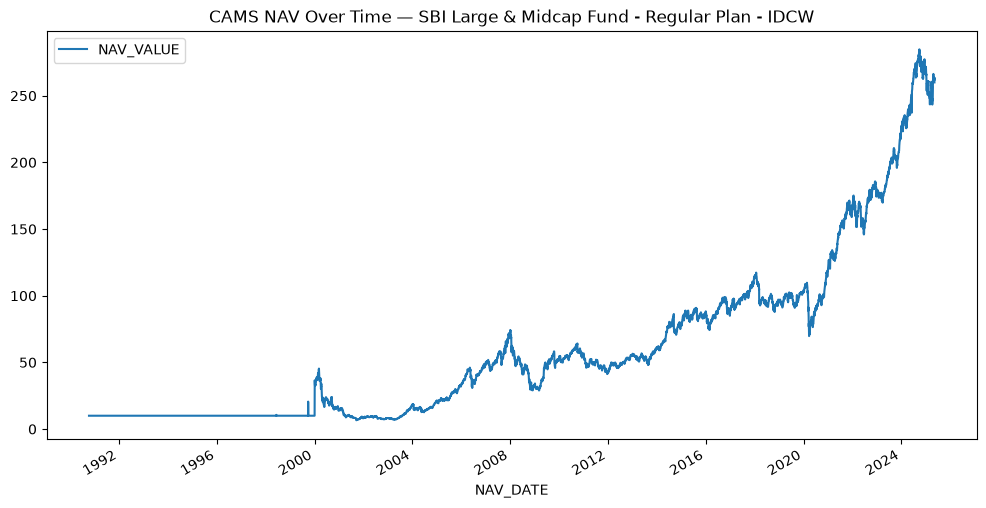

In [50]:
cams_top = cams_top.reset_index()
top_prodcode = cams_top.iloc[0]["PRODCODE"]

top_name = cams_metadata.loc[
    cams_metadata["PRODCODE"] == top_prodcode,
    "NAME"
].iloc[0]

cams_plot = (
    cams_navs[
        cams_navs["PRODCODE"] == top_prodcode
    ]
    .sort_values("NAV_DATE")
)

cams_plot.plot(
    x="NAV_DATE",
    y="NAV_VALUE",
    figsize=(12, 6),
    title=f"CAMS NAV Over Time — {top_name}"
)

<Axes: title={'center': 'Kfintech NAV Over Time — UTI Unit Linked Insurance Plan - Regular Plan'}, xlabel='NAVDATE'>

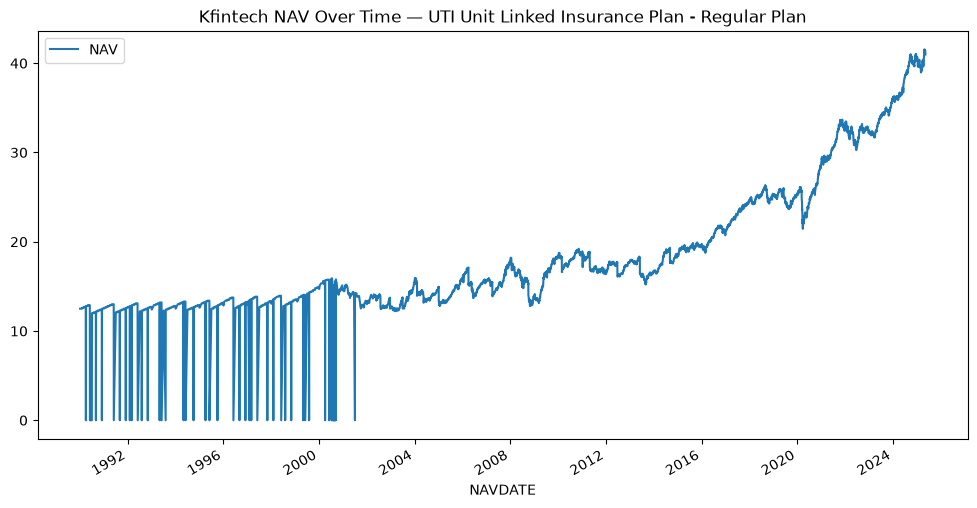

In [51]:
top_fcode_id = kfin_top.iloc[0]["FCODE_DESC_ID"]

top_name = kfintech_metadata.loc[
    kfintech_metadata["FCODE_DESC_ID"] == top_fcode_id,
    "FUNDDESC"
].iloc[0]

kfin_plot = kfintech_navs[
    kfintech_navs["FCODE_DESC_ID"] == top_fcode_id
].sort_values("NAVDATE")

kfin_plot.plot(
    x="NAVDATE",
    y="NAV",
    figsize=(12, 6),
    title=f"Kfintech NAV Over Time — {top_name}"
)

Top CAMS product: Franklin India PRIMA FUND - Growth
Total return: 16777.603573792192 %


<Axes: title={'center': 'CAMS NAV Over Time — Franklin India PRIMA FUND - Growth'}, xlabel='NAV_DATE'>

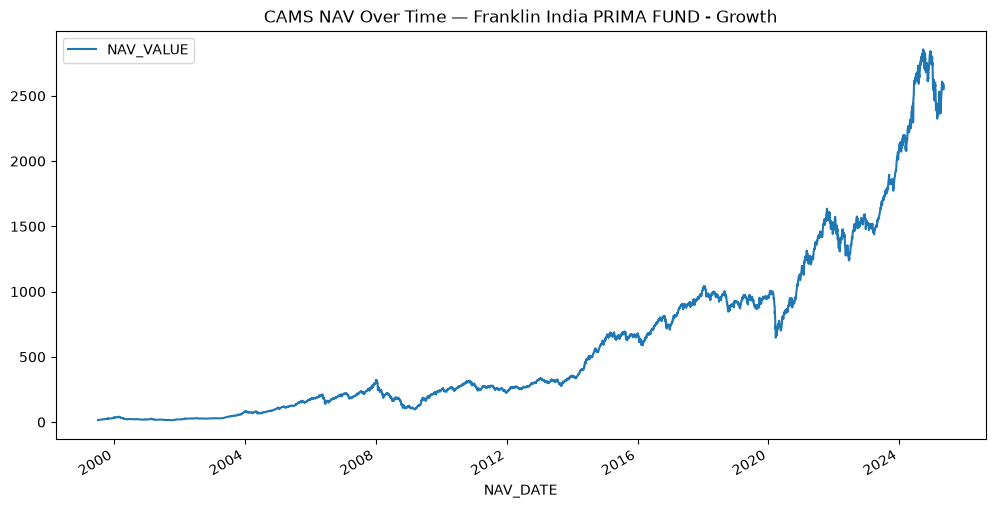

In [52]:
cams_top_return = (
    cams_overall[
        (cams_overall["total_return_%"] > 0) &
        (cams_overall["end_date"].dt.year == 2025)
    ]
    .sort_values("total_return_%", ascending=False)
)

top_prodcode = cams_top_return.index[0]

top_name = cams_metadata.loc[
    cams_metadata["PRODCODE"] == top_prodcode,
    "NAME"
].iloc[0]

cams_plot = cams_navs[
    cams_navs["PRODCODE"] == top_prodcode
].sort_values("NAV_DATE")

print("Top CAMS product:", top_name)
print("Total return:", cams_top_return.iloc[0]["total_return_%"], "%")

cams_plot.plot(
    x="NAV_DATE",
    y="NAV_VALUE",
    figsize=(12, 6),
    title=f"CAMS NAV Over Time — {top_name}"
)

Top Kfintech product id: 3238
Top Kfintech product name: UTI Money Market Fund - Regular Plan
Total return: 68900.54743633608 %


<Axes: title={'center': 'Kfintech NAV Over Time — UTI Money Market Fund - Regular Plan'}, xlabel='NAVDATE'>

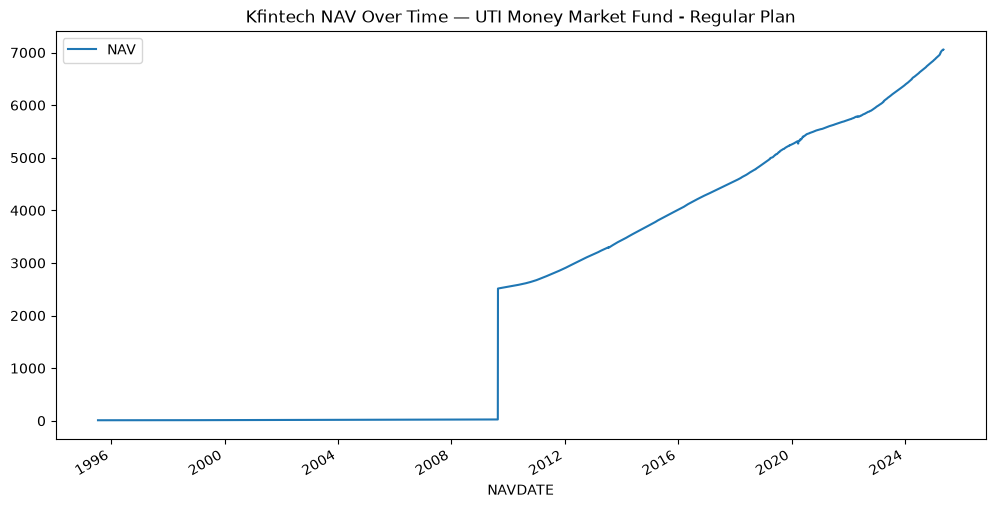

In [53]:
kfin_top_return = (
    kfin_overall[
        (kfin_overall["total_return_%"] > 0) &
        (kfin_overall["end_date"].dt.year == 2025)
    ]
    .sort_values("total_return_%", ascending=False)
)

top_fcode_id = kfin_top_return.index[0]

top_name = kfintech_metadata.loc[
    kfintech_metadata["FCODE_DESC_ID"] == top_fcode_id,
    "FUNDDESC"
].iloc[0]

kfin_plot = kfintech_navs[
    kfintech_navs["FCODE_DESC_ID"] == top_fcode_id
].sort_values("NAVDATE")

print("Top Kfintech product id:", top_fcode_id)
print("Top Kfintech product name:", top_name)
print("Total return:", kfin_top_return.iloc[0]["total_return_%"], "%")

kfin_plot.plot(
    x="NAVDATE",
    y="NAV",
    figsize=(12, 6),
    title=f"Kfintech NAV Over Time — {top_name}"
)

In [54]:
kfintech_navs["NAV_CHANGE_%"] = (
    kfintech_navs
    .groupby("FCODE_DESC_ID")["NAV"]
    .pct_change()
    * 100
)

top_product = (
    kfintech_navs[
        kfintech_navs["FCODE_DESC_ID"] == top_fcode_id
    ]
    .sort_values("NAVDATE")
    .copy()
)

# Find positions where absolute NAV change > 100%
large_changes = top_product[
    top_product["NAV_CHANGE_%"].abs() > 100
]

print("Number of >100% changes:", len(large_changes))

for idx in large_changes.index:
    pos = top_product.index.get_loc(idx)

    around = top_product.iloc[
        max(0, pos - 3): pos + 4
    ]

    print("\n" + "=" * 80)
    print(f"Massive change at: {top_product.loc[idx, 'NAVDATE']}")
    print("=" * 80)

    print(
        around[
            ["NAVDATE", "NAV", "NAV_CHANGE_%"]
        ].to_string(index=False)
    )

Number of >100% changes: 1

Massive change at: 2009-08-22 00:00:00
   NAVDATE       NAV  NAV_CHANGE_%
2009-08-19   25.1274      0.013135
2009-08-20   25.1308      0.013531
2009-08-21   25.1341      0.013131
2009-08-22 2513.7463   9901.338023
2009-08-23 2514.0799      0.013271
2009-08-24 2514.4153      0.013341
2009-08-25 2514.7394      0.012890


In [55]:
suspicious_kfin = kfintech_navs[
    kfintech_navs["NAV_CHANGE_%"].abs() > 100
].copy()

num_codes_kfin = suspicious_kfin["FCODE_DESC_ID"].nunique()

print(
    "Number of Kfintech codes with suspicious records:",
    num_codes_kfin
)

Number of Kfintech codes with suspicious records: 549


In [56]:
suspicious_cams = cams_navs[
    cams_navs["RETURN"].abs() > 1
].copy()

num_codes_cams = suspicious_cams["PRODCODE"].nunique()

print(
    "Number of CAMS products with suspicious records:",
    num_codes_cams
)

Number of CAMS products with suspicious records: 203


In [57]:
last_fluctuation = (
    suspicious_kfin
    .groupby("FCODE_DESC_ID")["NAVDATE"]
    .max()
    .rename("last_fluctuation_date")
)

last_fluctuation_cams = (
    suspicious_cams
    .groupby("PRODCODE")["NAV_DATE"]
    .max()
    .rename("last_fluctuation_date")
)

In [58]:
kfin_adjusted = kfin_overall.copy()

kfin_adjusted = kfin_adjusted.join(last_fluctuation)

kfin_adjusted["adjusted_start_date"] = (
    kfin_adjusted["last_fluctuation_date"]
)


cams_adjusted = cams_overall.copy()

cams_adjusted = cams_adjusted.join(last_fluctuation_cams)

cams_adjusted["adjusted_start_date"] = (
    cams_adjusted["last_fluctuation_date"]
)

In [59]:
kfin_dates = kfintech_navs[
    ["FCODE_DESC_ID", "NAVDATE", "NAV"]
].sort_values(["FCODE_DESC_ID", "NAVDATE"])

adjusted_starts = (
    kfin_dates
    .merge(
        last_fluctuation.reset_index(),
        on="FCODE_DESC_ID",
        how="inner"
    )
)

adjusted_starts = adjusted_starts[
    adjusted_starts["NAVDATE"] > adjusted_starts["last_fluctuation_date"]
]

adjusted_starts = (
    adjusted_starts
    .groupby("FCODE_DESC_ID")
    .first()
)

In [60]:
cams_dates = cams_navs[
    ["PRODCODE", "NAV_DATE", "NAV_VALUE"]
].sort_values(["PRODCODE", "NAV_DATE"])

adjusted_starts_cams = (
    cams_dates
    .merge(
        last_fluctuation_cams.reset_index(),
        on="PRODCODE",
        how="inner"
    )
)

adjusted_starts_cams = adjusted_starts_cams[
    adjusted_starts_cams["NAV_DATE"] >
    adjusted_starts_cams["last_fluctuation_date"]
]

adjusted_starts_cams = (
    adjusted_starts_cams
    .groupby("PRODCODE")
    .first()
)

In [61]:
kfin_adjusted.loc[
    adjusted_starts.index,
    "start_date"
] = adjusted_starts["NAVDATE"]

kfin_adjusted.loc[
    adjusted_starts.index,
    "start_nav"
] = adjusted_starts["NAV"]


cams_adjusted.loc[
    adjusted_starts_cams.index,
    "start_date"
] = adjusted_starts_cams["NAV_DATE"]

cams_adjusted.loc[
    adjusted_starts_cams.index,
    "start_nav"
] = adjusted_starts_cams["NAV_VALUE"]

In [62]:
kfin_adjusted["duration_years"] = (
    kfin_adjusted["end_date"] -
    kfin_adjusted["start_date"]
).dt.days / 365.25


cams_adjusted["duration_years"] = (
    cams_adjusted["end_date"] -
    cams_adjusted["start_date"]
).dt.days / 365.25

In [63]:
kfin_adjusted["total_return_%"] = (
    (
        kfin_adjusted["end_nav"] /
        kfin_adjusted["start_nav"]
    ) - 1
) * 100


cams_adjusted["total_return_%"] = (
    (
        cams_adjusted["end_nav"] /
        cams_adjusted["start_nav"]
    ) - 1
) * 100

In [64]:
kfin_adjusted["return_per_year_%"] = (
    kfin_adjusted["total_return_%"] /
    kfin_adjusted["duration_years"]
)

cams_adjusted["return_per_year_%"] = (
    cams_adjusted["total_return_%"] /
    cams_adjusted["duration_years"]
)

In [65]:
updated = kfin_overall[
    kfin_overall["start_date"] != kfin_adjusted["start_date"]
]

comparison = updated[
    ["start_date", "start_nav", "total_return_%"]
].join(
    kfin_adjusted[
        ["start_date", "start_nav", "total_return_%"]
    ],
    lsuffix="_original",
    rsuffix="_adjusted"
)

comparison

,start_date_original,start_nav_original,total_return_%_original,start_date_adjusted,start_nav_adjusted,total_return_%_adjusted
FCODE_DESC_ID,,,,,,
86,2016-09-12,10.0000,21.714000,2016-09-16,10.0156,21.524422
87,2016-09-12,10.0000,21.714000,2016-09-16,10.0156,21.524422
88,2016-09-12,10.0000,18.577000,2016-09-16,10.0141,18.410042
89,2016-09-12,10.0000,18.577000,2016-09-16,10.0141,18.410042
150,1993-03-31,10.0000,362.900000,2005-04-12,13.8500,234.223827
...,...,...,...,...,...,...
14429,2005-06-15,10.0000,9988.687000,2012-08-06,1000.5100,0.835444
14430,2005-06-15,10.0000,9992.936000,2012-08-06,1001.1036,0.818097
14431,2005-06-15,10.0000,41009.323000,2012-08-06,1671.7598,145.904483


In [66]:
updated_cams = cams_overall[
    cams_overall["start_date"] != cams_adjusted["start_date"]
]

comparison_cams = updated_cams[
    ["start_date", "start_nav", "total_return_%"]
].join(
    cams_adjusted[
        ["start_date", "start_nav", "total_return_%"]
    ],
    lsuffix="_original",
    rsuffix="_adjusted"
)

comparison_cams

,start_date_original,start_nav_original,total_return_%_original,start_date_adjusted,start_nav_adjusted,total_return_%_adjusted
PRODCODE,,,,,,
B102G,1999-03-31,10.0000,463.200000,2001-09-24,4.8600,1058.847737
B103D,1999-04-09,10.0000,124.600000,2001-10-22,4.5100,398.004435
B107WD,2000-01-06,1.0000,983.050000,2001-04-19,11.1848,-3.167692
B134,2003-03-10,1.0000,1312.330000,2003-05-30,15.9223,-11.298619
B135,2000-01-06,1.0000,978.730000,2003-06-11,10.7517,0.331110
...,...,...,...,...,...,...
TTMHMS,2019-06-15,384.1589,-53.868386,2021-10-01,166.4395,6.476347
TTMHWS,2019-06-15,387.6188,-53.868388,2021-10-01,167.9386,6.476296
TTMMPS,2019-06-15,384.1589,-53.868386,2021-10-01,166.4395,6.476347


In [67]:
kfin_overall.loc[
    kfin_adjusted.index,
    "start_date"
] = kfin_adjusted["start_date"]

kfin_overall.loc[
    kfin_adjusted.index,
    "start_nav"
] = kfin_adjusted["start_nav"]


cams_overall.loc[
    cams_adjusted.index,
    "start_date"
] = cams_adjusted["start_date"]

cams_overall.loc[
    cams_adjusted.index,
    "start_nav"
] = cams_adjusted["start_nav"]

In [68]:
updated_ids = updated.index

kfin_overall.loc[
    updated_ids,
    "start_date"
] = kfin_adjusted.loc[
    updated_ids,
    "start_date"
]

kfin_overall.loc[
    updated_ids,
    "start_nav"
] = kfin_adjusted.loc[
    updated_ids,
    "start_nav"
]

In [69]:
updated_ids_cams = updated_cams.index

cams_overall.loc[
    updated_ids_cams,
    "start_date"
] = cams_adjusted.loc[
    updated_ids_cams,
    "start_date"
]

cams_overall.loc[
    updated_ids_cams,
    "start_nav"
] = cams_adjusted.loc[
    updated_ids_cams,
    "start_nav"
]

In [70]:
kfin_overall.loc[updated_ids, "total_return_%"] = (
    (
        kfin_overall.loc[updated_ids, "end_nav"]
        / kfin_overall.loc[updated_ids, "start_nav"]
    ) - 1
) * 100

cams_overall.loc[updated_ids_cams, "total_return_%"] = (
    (
        cams_overall.loc[updated_ids_cams, "end_nav"]
        / cams_overall.loc[updated_ids_cams, "start_nav"]
    ) - 1
) * 100

In [71]:
kfin_overall.loc[updated_ids, "duration_years"] = (
    (
        kfin_overall.loc[updated_ids, "end_date"]
        - kfin_overall.loc[updated_ids, "start_date"]
    ).dt.days / 365.25
)

cams_overall.loc[updated_ids_cams, "duration_years"] = (
    (
        cams_overall.loc[updated_ids_cams, "end_date"]
        - cams_overall.loc[updated_ids_cams, "start_date"]
    ).dt.days / 365.25
)

In [72]:
kfin_overall.loc[updated_ids, "return_per_year_%"] = (
    kfin_overall.loc[updated_ids, "total_return_%"]
    / kfin_overall.loc[updated_ids, "duration_years"]
)

cams_overall.loc[updated_ids_cams, "return_per_year_%"] = (
    cams_overall.loc[updated_ids_cams, "total_return_%"]
    / cams_overall.loc[updated_ids_cams, "duration_years"]
)

In [73]:
kfin_overall.loc[updated_ids, "duration_group"] = (
    kfin_overall.loc[updated_ids, "duration_years"].astype(int)
)

cams_overall.loc[updated_ids_cams, "duration_group"] = (
    cams_overall.loc[updated_ids_cams, "duration_years"].astype(int)
)

In [74]:
kfin_overall.loc[
    updated_ids,
    [
        "start_date",
        "start_nav",
        "total_return_%",
        "duration_years",
        "return_per_year_%",
        "duration_group"
    ]
]

,start_date,start_nav,total_return_%,duration_years,return_per_year_%,duration_group
FCODE_DESC_ID,,,,,,
86,2016-09-16,10.0156,21.524422,2.989733,7.199446,2
87,2016-09-16,10.0156,21.524422,2.989733,7.199446,2
88,2016-09-16,10.0141,18.410042,2.989733,6.157754,2
89,2016-09-16,10.0141,18.410042,2.989733,6.157754,2
150,2005-04-12,13.8500,234.223827,20.073922,11.668065,20
...,...,...,...,...,...,...
14429,2012-08-06,1000.5100,0.835444,12.755647,0.065496,12
14430,2012-08-06,1001.1036,0.818097,12.755647,0.064136,12
14431,2012-08-06,1671.7598,145.904483,12.755647,11.438423,12


In [75]:
cams_overall.loc[
    updated_ids_cams,
    [
        "start_date",
        "start_nav",
        "total_return_%",
        "duration_years",
        "return_per_year_%",
        "duration_group"
    ]
]

,start_date,start_nav,total_return_%,duration_years,return_per_year_%,duration_group
PRODCODE,,,,,,
B102G,2001-09-24,4.8600,1058.847737,13.043121,81.180549,13
B103D,2001-10-22,4.5100,398.004435,12.966461,30.694915,12
B107WD,2001-04-19,11.1848,-3.167692,13.475702,-0.235067,13
B134,2003-05-30,15.9223,-11.298619,11.364819,-0.994175,11
B135,2003-06-11,10.7517,0.331110,11.331964,0.029219,11
...,...,...,...,...,...,...
TTMHMS,2021-10-01,166.4395,6.476347,0.358658,18.057144,0
TTMHWS,2021-10-01,167.9386,6.476296,0.358658,18.056999,0
TTMMPS,2021-10-01,166.4395,6.476347,0.358658,18.057144,0


In [76]:
print("Number of Kfintech funds after adjustment:", len(kfin_overall))
print("Number of CAMS funds after adjustment:", len(cams_overall))

Number of Kfintech funds after adjustment: 15497
Number of CAMS funds after adjustment: 26328


In [77]:
kfin_overall = kfin_overall[
    np.isfinite(kfin_overall["total_return_%"])
].copy()
print("Number of Kfintech funds after infinite values removed:", len(kfin_overall))

cams_overall = cams_overall[
    np.isfinite(cams_overall["total_return_%"])
].copy()

print("Number of CAMS funds after infinite values removed:", len(cams_overall))

Number of Kfintech funds after infinite values removed: 15486
Number of CAMS funds after infinite values removed: 26328


In [78]:
kfin_overall = kfin_overall[
    (kfin_overall["end_date"].dt.year == 2025) &
    (kfin_overall["total_return_%"] > 0)
].copy()
print("Kfintech:", len(kfin_overall))

cams_overall = cams_overall[
    (cams_overall["end_date"].dt.year == 2025) &
    (cams_overall["total_return_%"] > 0)
].copy()
print("CAMS:", len(cams_overall))

Kfintech: 3762
CAMS: 5314


Top 10 Kfintech funds by total return:


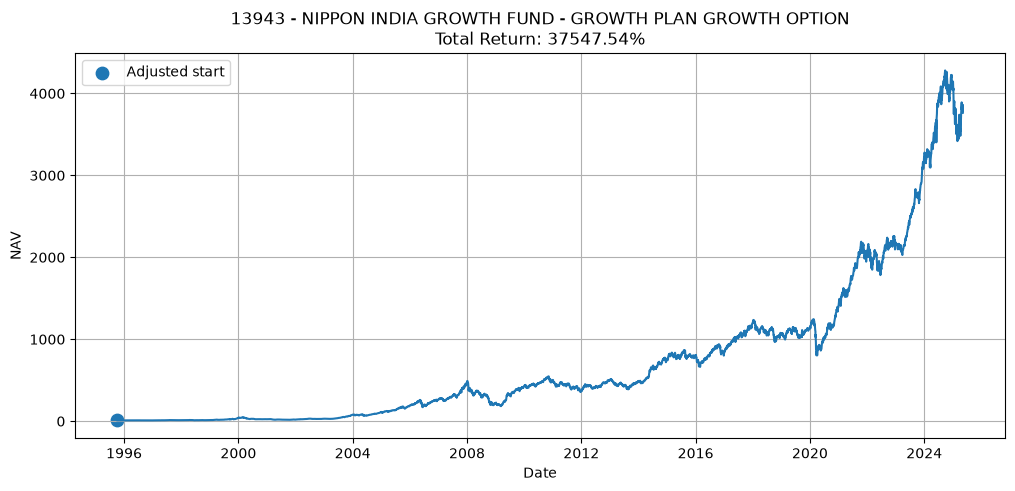

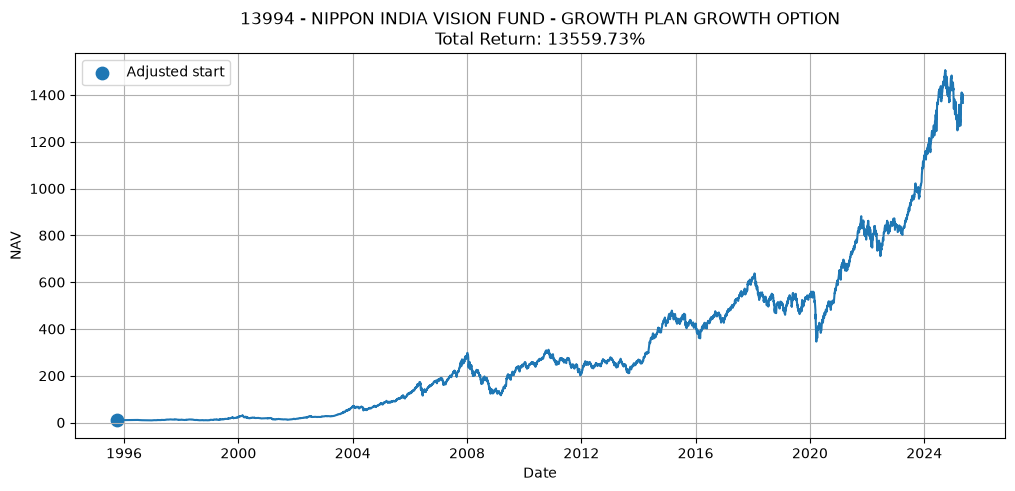

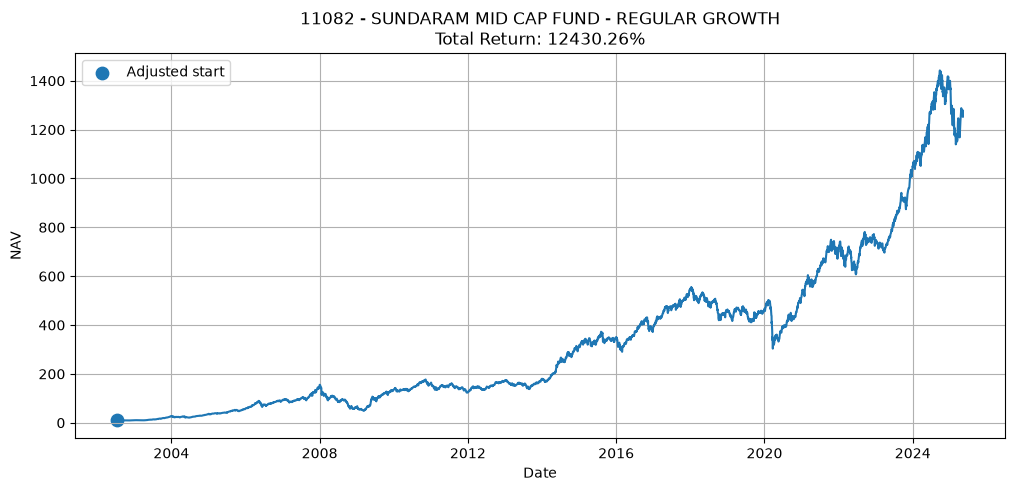

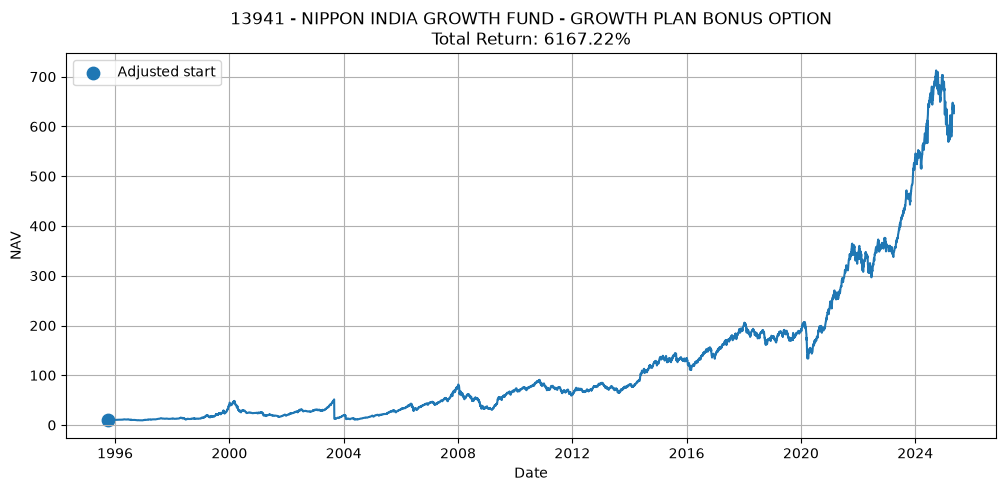

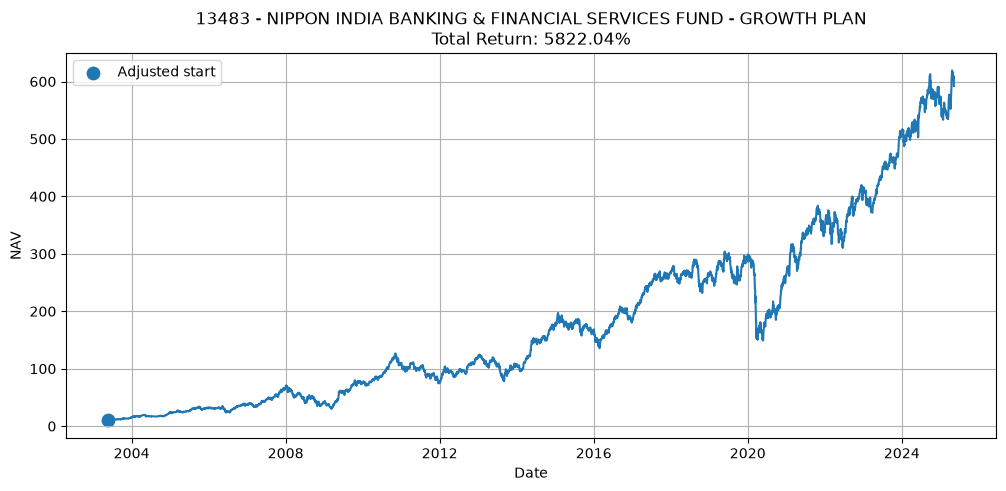

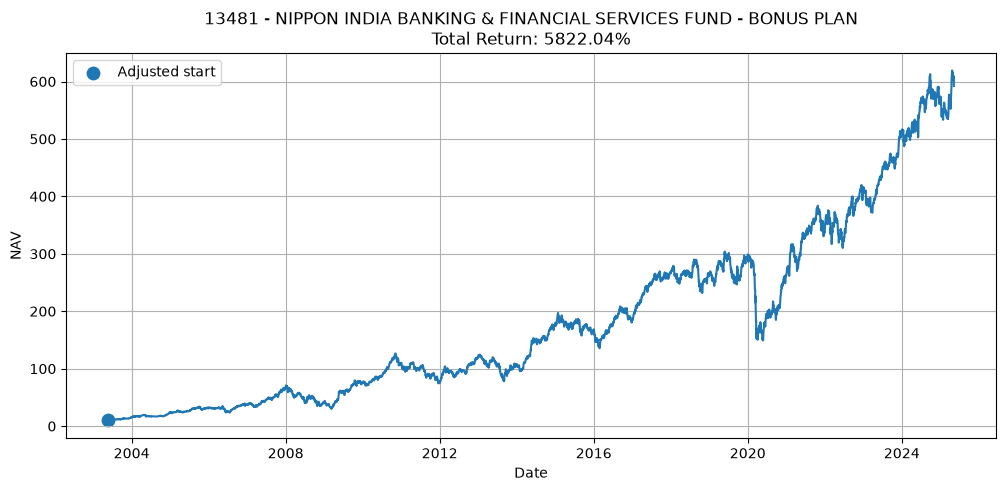

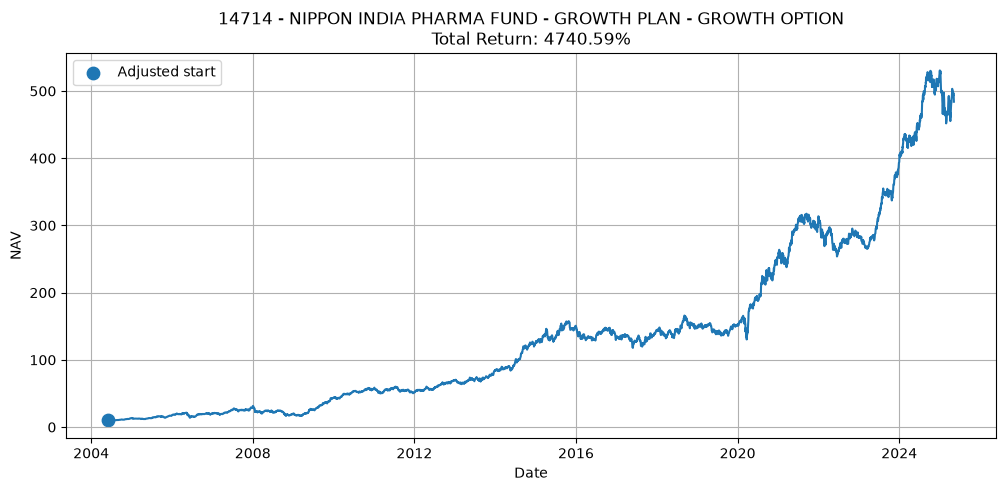

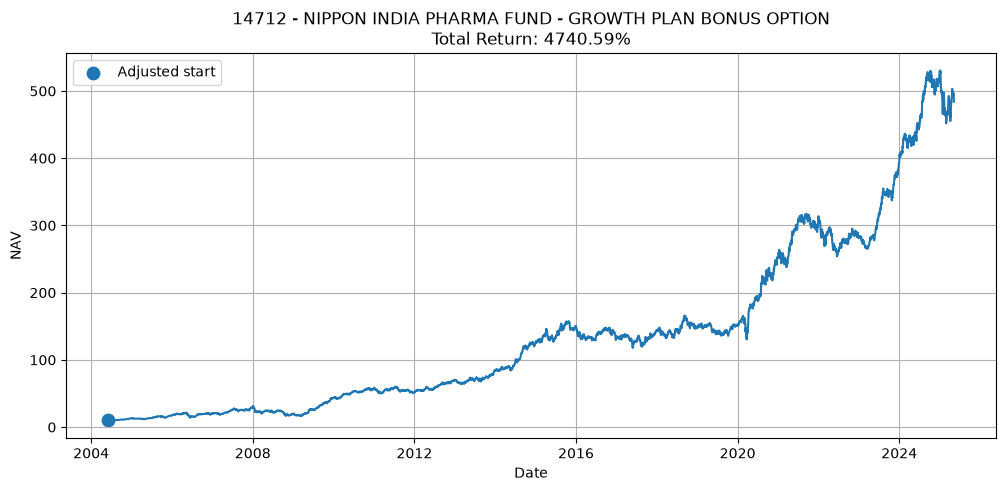

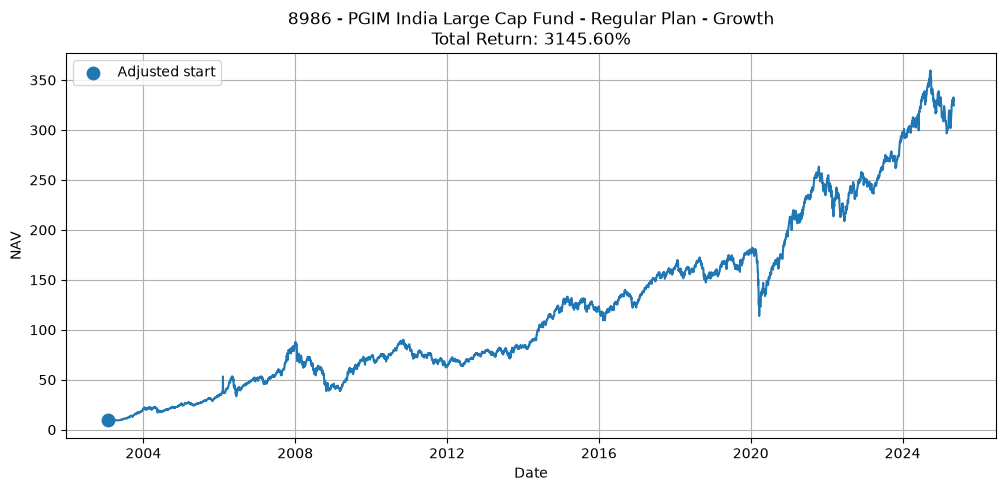

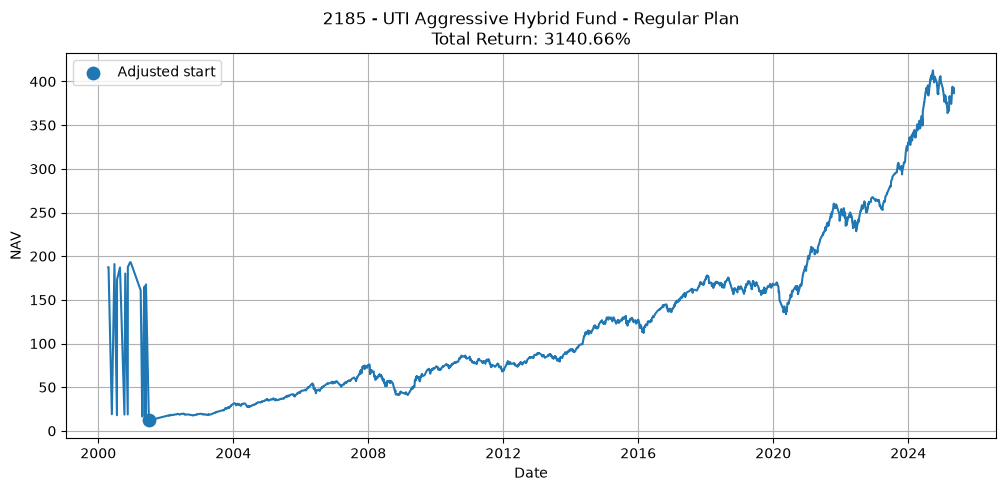

In [79]:
import matplotlib.pyplot as plt

print("Top 10 Kfintech funds by total return:")

top_ids = (
    kfin_overall
    .sort_values("total_return_%", ascending=False)
    .index[:10]
)

for fcode_id in top_ids:

    data = (
        kfintech_navs[
            kfintech_navs["FCODE_DESC_ID"] == fcode_id
        ]
        .sort_values("NAVDATE")
    )

    start_date = kfin_overall.loc[fcode_id, "start_date"]
    start_nav = kfin_overall.loc[fcode_id, "start_nav"]
    total_return = kfin_overall.loc[fcode_id, "total_return_%"]

    # Get fund code  from metadata
    fund_name = kfintech_metadata.loc[
        kfintech_metadata["FCODE_DESC_ID"] == fcode_id,
        "FUNDDESC"
    ].iloc[0]
    
    # Get fund name from metadata
    fund_name = kfintech_metadata.loc[
        kfintech_metadata["FCODE_DESC_ID"] == fcode_id,
        "FUNDDESC"
    ].iloc[0]
    

    plt.figure(figsize=(12, 5))

    plt.plot(
        data["NAVDATE"],
        data["NAV"]
    )

    plt.scatter(
        start_date,
        start_nav,
        s=80,
        label="Adjusted start"
    )

    plt.title(
        f"{fcode_id} - {fund_name}\n"
        f"Total Return: {total_return:.2f}%"
    )

    plt.xlabel("Date")
    plt.ylabel("NAV")
    plt.legend()
    plt.grid(True)
    plt.show()

Top 10 CAMS funds by total return:


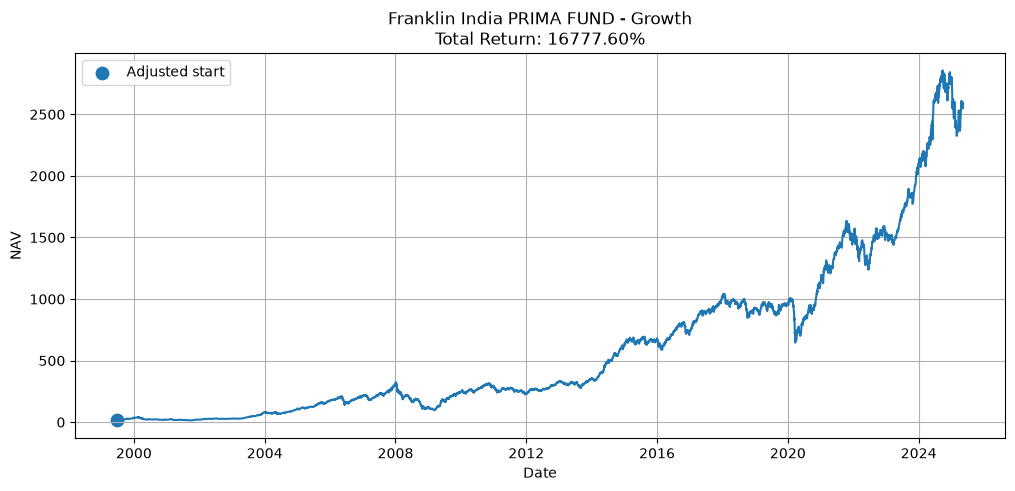

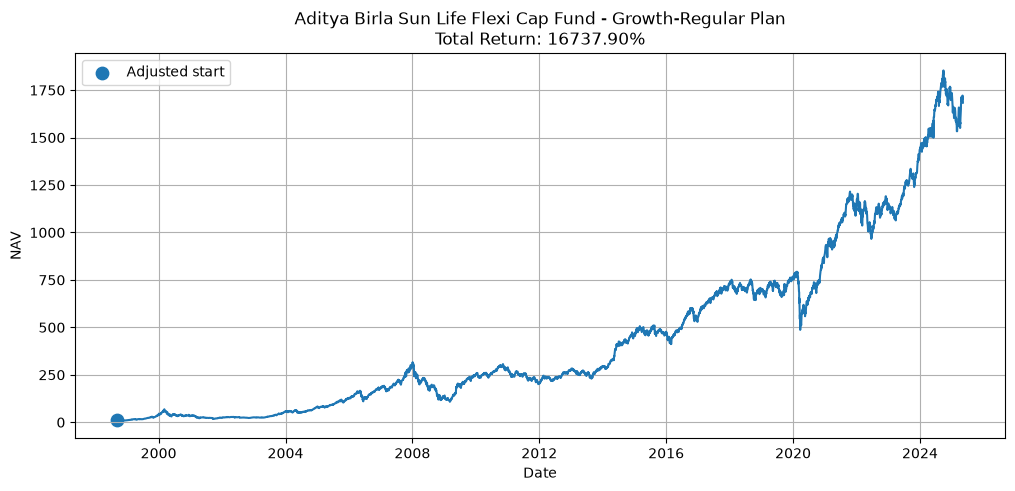

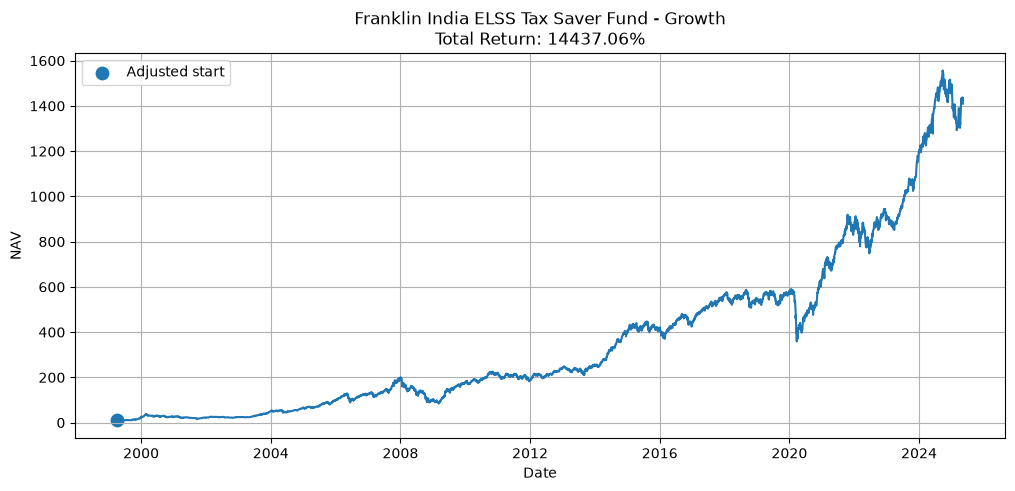

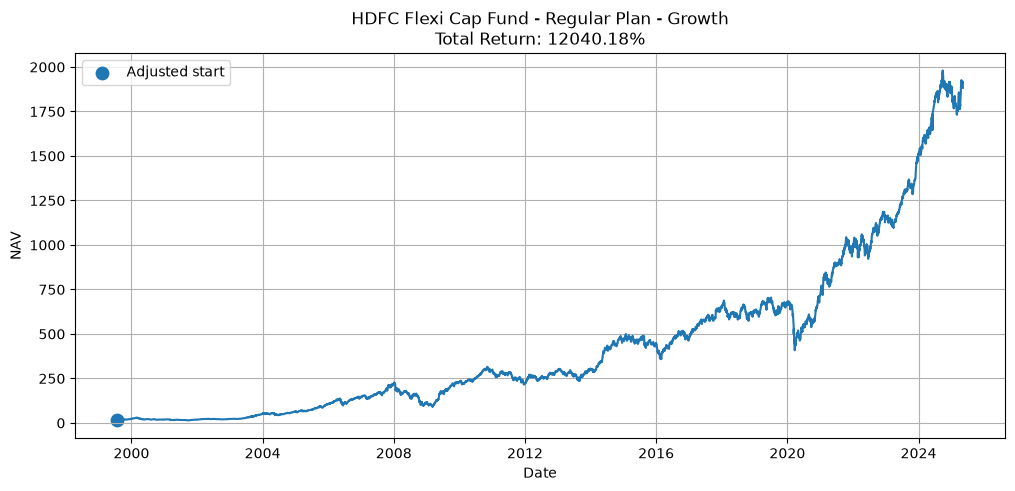

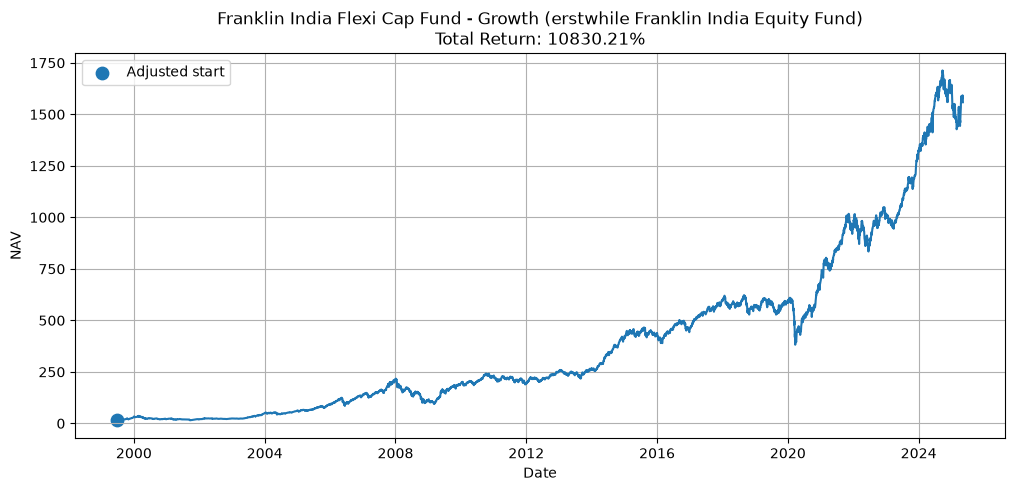

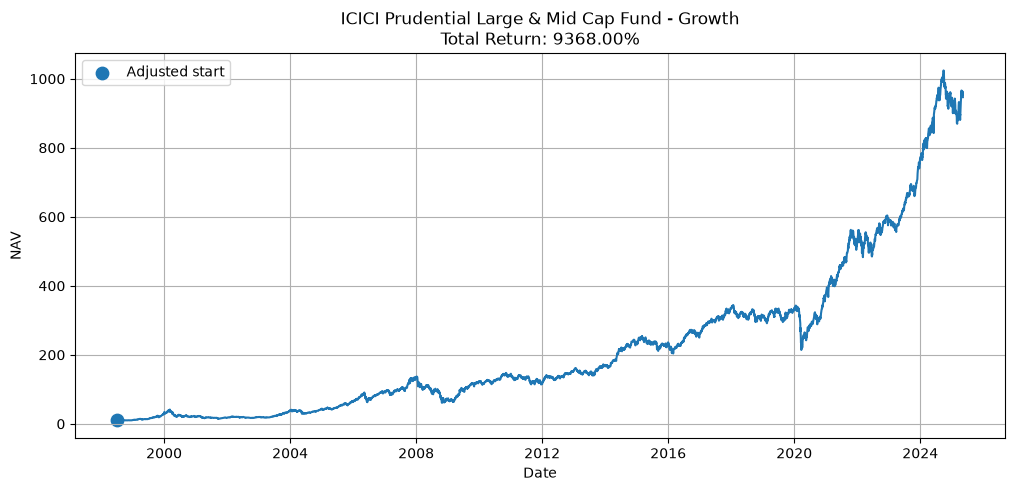

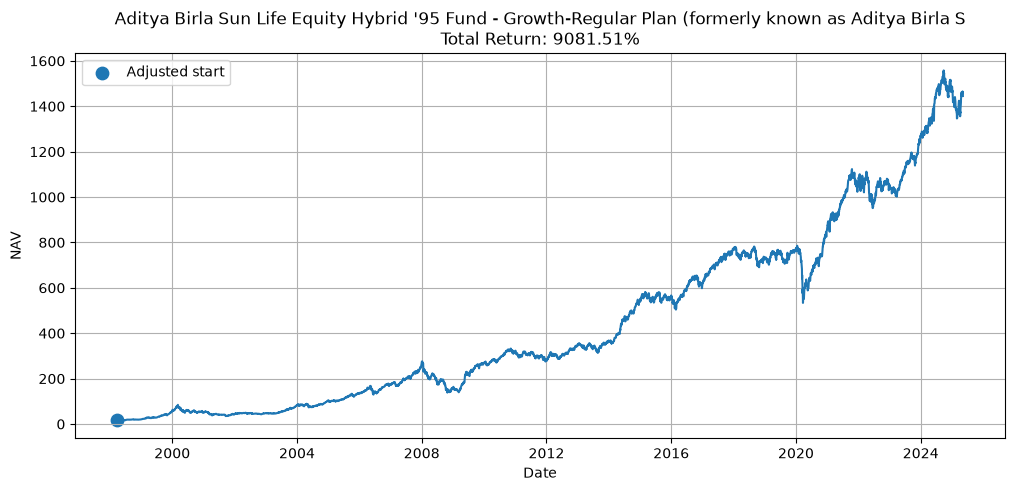

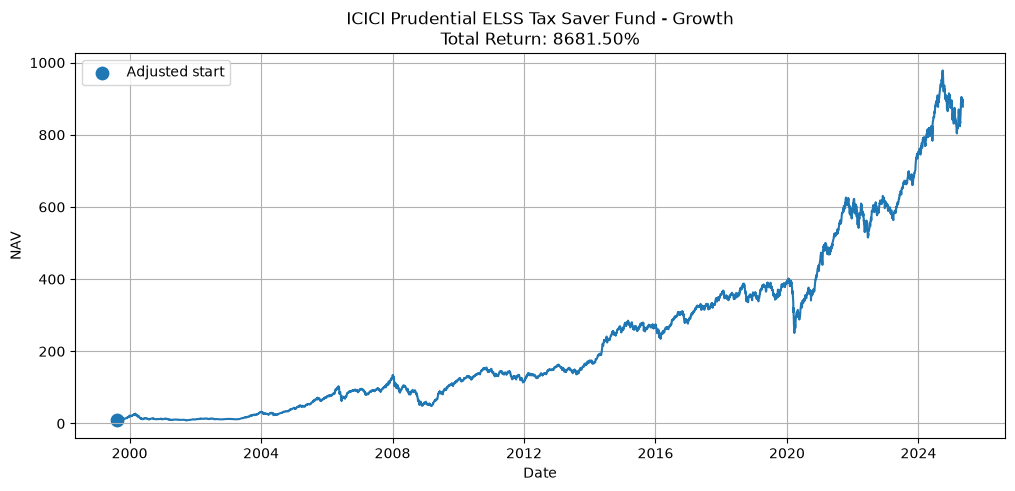

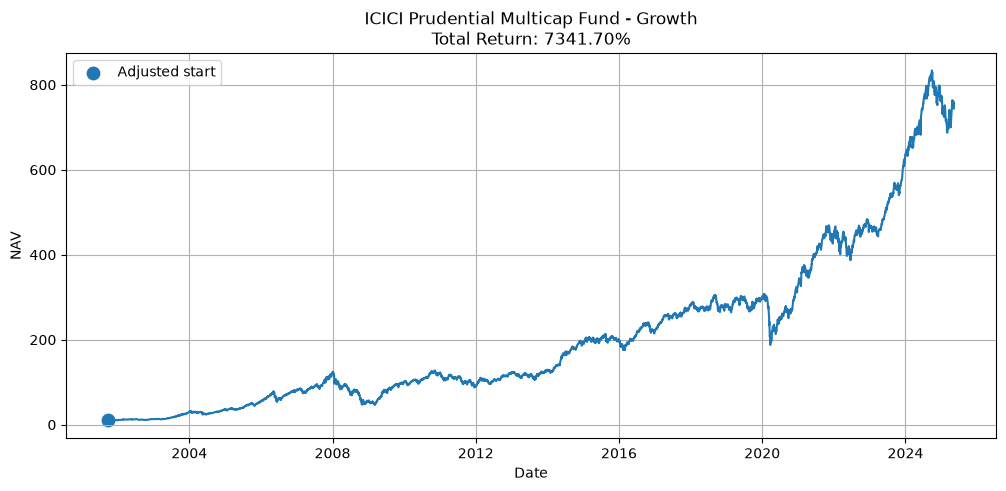

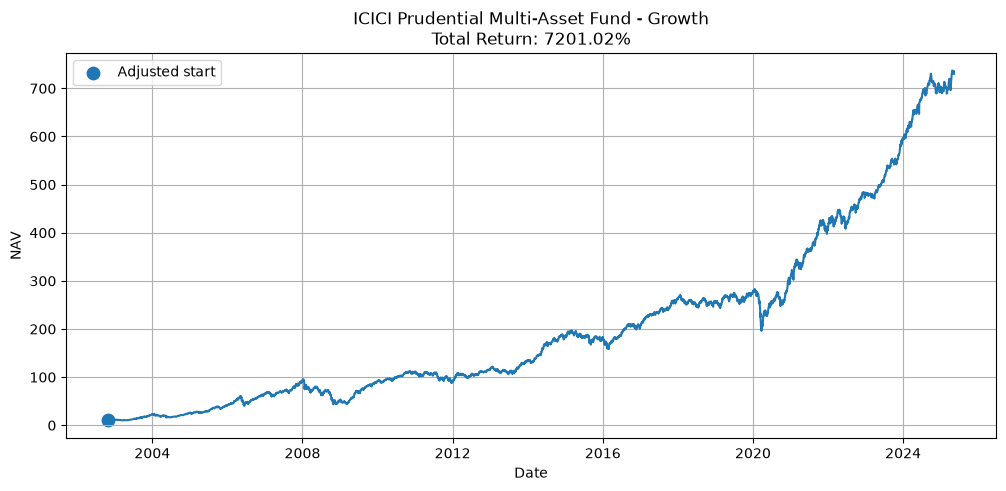

In [80]:
print("Top 10 CAMS funds by total return:")
top_ids = (
    cams_overall
    .sort_values("total_return_%", ascending=False)
    .index[:10]
)

for prodcode in top_ids:

    data = (
        cams_navs[
            cams_navs["PRODCODE"] == prodcode
        ]
        .sort_values("NAV_DATE")
    )

    start_date = cams_overall.loc[prodcode, "start_date"]
    start_nav = cams_overall.loc[prodcode, "start_nav"]
    total_return = cams_overall.loc[prodcode, "total_return_%"]

    # Get fund name from metadata
    fund_name = cams_metadata.loc[
        cams_metadata["PRODCODE"] == prodcode,
        "NAME"
    ].iloc[0]

    plt.figure(figsize=(12, 5))

    plt.plot(
        data["NAV_DATE"],
        data["NAV_VALUE"]
    )

    plt.scatter(
        start_date,
        start_nav,
        s=80,
        label="Adjusted start"
    )

    plt.title(
        f"{fund_name}\n"
        f"Total Return: {total_return:.2f}%"
    )

    plt.xlabel("Date")
    plt.ylabel("NAV")
    plt.legend()
    plt.grid(True)
    plt.show()

In [81]:
print("KFIN overall info:")
print(kfin_overall.info())
kfin_overall.head(10)

KFIN overall info:
<class 'pandas.DataFrame'>
Index: 3762 entries, 67 to 15191
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   start_date         3762 non-null   datetime64[us]
 1   end_date           3762 non-null   datetime64[us]
 2   observations       3762 non-null   int64         
 3   start_nav          3762 non-null   float64       
 4   end_nav            3762 non-null   float64       
 5   volatility         3762 non-null   float64       
 6   total_return_%     3762 non-null   float64       
 7   duration_years     3762 non-null   float64       
 8   return_per_year_%  3762 non-null   float64       
 9   duration_group     3762 non-null   int64         
dtypes: datetime64[us](2), float64(6), int64(2)
memory usage: 452.3 KB
None


,start_date,end_date,observations,start_nav,end_nav,volatility,total_return_%,duration_years,return_per_year_%,duration_group
FCODE_DESC_ID,,,,,,,,,,
67,2022-08-22,2025-05-09,656,10.0000,10.9179,0.001987,9.179000,2.713210,3.383077,2
68,2022-08-22,2025-05-09,656,10.0000,12.0770,0.000467,20.770000,2.713210,7.655139,2
69,2022-08-22,2025-05-09,656,10.0000,10.8363,0.001979,8.363000,2.713210,3.082327,2
70,2022-08-22,2025-05-09,656,10.0000,11.9801,0.000466,19.801000,2.713210,7.297997,2
100,2013-01-01,2025-05-09,3039,15.3500,85.4200,0.010462,456.482085,12.350445,36.960781,12
101,2013-01-01,2025-05-09,3039,16.4600,118.9500,0.010248,622.660996,12.350445,50.416078,12
102,2009-09-14,2025-05-09,3852,10.0000,46.8900,0.010724,368.900000,15.649555,23.572555,15
103,2009-09-14,2025-05-09,3852,10.0000,103.7200,0.010126,937.200000,15.649555,59.886686,15
116,2013-01-01,2025-05-09,2980,11.4919,27.4489,0.000824,138.854323,12.350445,11.242860,12


In [82]:
print("CAMS overall info:")
print(cams_overall.info())
cams_overall.head(10)

CAMS overall info:
<class 'pandas.DataFrame'>
Index: 5314 entries, B02 to ZZOVER
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype        
---  ------             --------------  -----        
 0   start_date         5314 non-null   datetime64[s]
 1   end_date           5314 non-null   datetime64[s]
 2   observations       5314 non-null   int64        
 3   start_nav          5314 non-null   float64      
 4   end_nav            5314 non-null   float64      
 5   volatility         5314 non-null   float64      
 6   total_return_%     5314 non-null   float64      
 7   duration_years     5314 non-null   float64      
 8   return_per_year_%  5314 non-null   float64      
 9   duration_group     5314 non-null   int64        
dtypes: datetime64[s](2), float64(6), int64(2)
memory usage: 614.1 KB
None


,start_date,end_date,observations,start_nav,end_nav,volatility,total_return_%,duration_years,return_per_year_%,duration_group
PRODCODE,,,,,,,,,,
B02,1996-03-31,2025-05-09,7140,10.00,181.1800,0.016623,1711.800000,29.106092,58.812431,29
B02D,2010-08-09,2025-05-09,3632,86.89,181.1800,0.010075,108.516515,14.748802,7.357649,14
B02DZ,2013-01-02,2025-05-09,3040,83.08,413.5900,0.009347,397.821377,12.347707,32.218239,12
B02G,2008-03-07,2025-05-09,4223,10.00,55.5100,0.011876,455.100000,17.171800,26.502754,17
B02GK,2009-02-10,2025-05-09,3998,5.15,55.5100,0.010596,977.864078,16.240931,60.209854,16
B02GZ,2013-01-01,2025-05-09,3041,11.97,61.8500,0.009331,416.708438,12.350445,33.740358,12
B02Z,2013-01-01,2025-05-09,3041,82.65,413.5900,0.009345,400.411373,12.350445,32.420806,12
B100A,2022-01-13,2025-05-09,794,10.00,15.0626,0.013253,50.626000,3.318275,15.256722,3
B100B,2022-02-03,2025-05-09,793,10.00,15.0647,0.013262,50.647000,3.260780,15.532172,3


In [83]:
kfin_overall["SOURCE"] = "KFINTECH"
kfin_overall["PRODUCT_ID"] = kfin_overall.index
kfin_overall = kfin_overall.reset_index(drop=True)

cams_overall["SOURCE"] = "CAMS"
cams_overall["PRODUCT_ID"] = cams_overall.index
cams_overall = cams_overall.reset_index(drop=True)

In [84]:
combined_overall = pd.concat(
    [kfin_overall, cams_overall],
    ignore_index=True
)

In [85]:
print("Combined funds:", len(combined_overall))
print(combined_overall.info())

Combined funds: 9076
<class 'pandas.DataFrame'>
RangeIndex: 9076 entries, 0 to 9075
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   start_date         9076 non-null   datetime64[us]
 1   end_date           9076 non-null   datetime64[us]
 2   observations       9076 non-null   int64         
 3   start_nav          9076 non-null   float64       
 4   end_nav            9076 non-null   float64       
 5   volatility         9076 non-null   float64       
 6   total_return_%     9076 non-null   float64       
 7   duration_years     9076 non-null   float64       
 8   return_per_year_%  9076 non-null   float64       
 9   duration_group     9076 non-null   int64         
 10  SOURCE             9076 non-null   str           
 11  PRODUCT_ID         9076 non-null   object        
dtypes: datetime64[us](2), float64(6), int64(2), object(1), str(1)
memory usage: 902.3+ KB
None


In [86]:
combined_overall

,start_date,end_date,observations,start_nav,end_nav,volatility,total_return_%,duration_years,return_per_year_%,duration_group,SOURCE,PRODUCT_ID
0,2022-08-22,2025-05-09,656,10.0000,10.9179,0.001987,9.179000,2.713210,3.383077,2,KFINTECH,67
1,2022-08-22,2025-05-09,656,10.0000,12.0770,0.000467,20.770000,2.713210,7.655139,2,KFINTECH,68
2,2022-08-22,2025-05-09,656,10.0000,10.8363,0.001979,8.363000,2.713210,3.082327,2,KFINTECH,69
3,2022-08-22,2025-05-09,656,10.0000,11.9801,0.000466,19.801000,2.713210,7.297997,2,KFINTECH,70
4,2013-01-01,2025-05-09,3039,15.3500,85.4200,0.010462,456.482085,12.350445,36.960781,12,KFINTECH,100
...,...,...,...,...,...,...,...,...,...,...,...,...
9071,2024-11-13,2025-05-09,117,10.0000,12.7343,0.009161,27.343000,0.484600,56.423903,0,CAMS,ZZGFOF
9072,2024-02-26,2025-05-09,294,9.9995,15.2507,0.008650,52.514626,1.199179,43.792162,1,CAMS,ZZGOLD
9073,2024-01-17,2025-05-09,394,99.9950,108.4562,0.000124,8.461623,1.308693,6.465707,1,CAMS,ZZLIQD
9074,2023-11-08,2025-05-09,367,10.0000,12.8732,0.010175,28.732000,1.500342,19.150297,1,CAMS,ZZN250


In [87]:
combined_overall = combined_overall[
    [
        "SOURCE",
        "PRODUCT_ID",
        "start_date",
        "end_date",
        "duration_years",
        "duration_group",
        "observations",
        "start_nav",
        "end_nav",
        "total_return_%",
        "return_per_year_%",
        "volatility"
    ]
].copy()

combined_overall = combined_overall.astype({
    "observations": "int64",
    "start_nav": "float64",
    "end_nav": "float64",
    "volatility": "float64",
    "total_return_%": "float64",
    "duration_years": "float64",
    "return_per_year_%": "float64",
    "duration_group": "int64",
    "SOURCE": "string",
    "PRODUCT_ID": "string"
})

combined_overall["start_date"] = pd.to_datetime(
    combined_overall["start_date"]
)

combined_overall["end_date"] = pd.to_datetime(
    combined_overall["end_date"]
)

combined_overall = combined_overall.rename(columns={
    "SOURCE": "source",
    "PRODUCT_ID": "product_id",
    "start_date": "start_date",
    "end_date": "end_date",
    "duration_years": "duration_years",
    "duration_group": "duration_group",
    "observations": "observations",
    "start_nav": "start_nav",
    "end_nav": "end_nav",
    "total_return_%": "total_return_pct",
    "return_per_year_%": "return_per_year_pct",
    "volatility": "volatility"
})

combined_overall = combined_overall.reset_index(drop=True)

In [88]:
combined_overall

,source,product_id,start_date,end_date,duration_years,duration_group,observations,start_nav,end_nav,total_return_pct,return_per_year_pct,volatility
0,KFINTECH,67,2022-08-22,2025-05-09,2.713210,2,656,10.0000,10.9179,9.179000,3.383077,0.001987
1,KFINTECH,68,2022-08-22,2025-05-09,2.713210,2,656,10.0000,12.0770,20.770000,7.655139,0.000467
2,KFINTECH,69,2022-08-22,2025-05-09,2.713210,2,656,10.0000,10.8363,8.363000,3.082327,0.001979
3,KFINTECH,70,2022-08-22,2025-05-09,2.713210,2,656,10.0000,11.9801,19.801000,7.297997,0.000466
4,KFINTECH,100,2013-01-01,2025-05-09,12.350445,12,3039,15.3500,85.4200,456.482085,36.960781,0.010462
...,...,...,...,...,...,...,...,...,...,...,...,...
9071,CAMS,ZZGFOF,2024-11-13,2025-05-09,0.484600,0,117,10.0000,12.7343,27.343000,56.423903,0.009161
9072,CAMS,ZZGOLD,2024-02-26,2025-05-09,1.199179,1,294,9.9995,15.2507,52.514626,43.792162,0.008650
9073,CAMS,ZZLIQD,2024-01-17,2025-05-09,1.308693,1,394,99.9950,108.4562,8.461623,6.465707,0.000124
9074,CAMS,ZZN250,2023-11-08,2025-05-09,1.500342,1,367,10.0000,12.8732,28.732000,19.150297,0.010175


In [89]:
from pathlib import Path

output_path = Path("../dataset/combined")
output_path.mkdir(parents=True, exist_ok=True)

combined_overall.to_parquet(
    output_path / "combined_overall.parquet",
    index=False
)
print("Saved:", output_path / "combined_overall.parquet")

Saved: ..\dataset\combined\combined_overall.parquet
